# Machine Learning for OSNR Estimation from Eye Diagrams Using Convolutional Neural Networks (CNNs)

<a href="https://colab.research.google.com/" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

**Runtime:** Google Colab → *Runtime ▸ Change runtime type ▸ T4 GPU* (the notebook also runs on CPU, more slowly).

## 1. Project Title and Abstract

**Abstract.** Optical performance monitoring (OPM) aims to estimate the health of an optical channel — most importantly its
optical signal‑to‑noise ratio (OSNR) — directly from the received signal. Classical eye‑diagram analysis extracts a handful of
hand‑crafted parameters (Q‑factor, eye opening, crossing level, jitter). In this project we instead let a convolutional neural
network (CNN) learn the relevant features directly from eye‑diagram images.

Because no public dataset of *eye‑diagram images* with OSNR and chromatic‑dispersion (CD) labels could be identified (Section 7),
we build our own dataset with a **physically motivated simulation of a 10 Gb/s NRZ‑OOK intensity‑modulation / direct‑detection
(IM/DD) link**: a band‑limited chirp‑free Mach–Zehnder modulator, an all‑pass chromatic‑dispersion transfer function applied to the
**optical field**, amplified‑spontaneous‑emission (ASE) noise calibrated to a target OSNR in a **0.1 nm (≈12.5 GHz) reference
bandwidth**, an optical band‑pass filter, square‑law detection of both polarisations, and an ITU‑T‑style 4th‑order Bessel–Thomson
receiver filter. Each received waveform is rendered as a 128×128 persistence‑style eye diagram.

A multi‑task CNN is trained to (i) regress OSNR in dB and (ii) classify the dominant impairment (clean / noise / dispersion /
both). The CNN is evaluated with MAE, MSE, RMSE and R² on a held‑out test set, on **OSNR/CD combinations never seen during
training**, and on an **off‑grid** set with continuous OSNR values and unseen CD values; it is compared with Random‑Forest and
SVR models trained on hand‑crafted eye features (in the spirit of Jargon *et al.*, 2009) and a fully connected network on raw pixels.

> ⚠️ **All results in this notebook are obtained on simulated data.** They are *not* laboratory measurements, and every number
> reported is computed by the code when the notebook is executed — nothing is hard‑coded.

## 2. Project Objectives

1. **Generate** optical eye diagrams under controlled OSNR (10–30 dB) and chromatic‑dispersion (0–800 ps/nm) conditions using a
   physically correct optical‑field simulation.
2. **Build** a labelled dataset (PNG images + `metadata.csv`) of ≥ 5 000 eye diagrams, with every image produced by an independent
   random bit sequence and noise realisation.
3. **Train** a CNN that estimates OSNR (dB) from an eye‑diagram image.
4. **Classify** the dominant optical impairment (clean / noise‑impaired / dispersion‑impaired / both) with a second CNN output head.
5. **Evaluate** with regression (MAE, MSE, RMSE, R²) and classification (accuracy, precision, recall, F1, confusion matrix) metrics,
   including generalisation to unseen parameter combinations and off‑grid values.
6. **Compare** against simpler baselines (Random Forest / SVR on hand‑crafted eye features, fully connected network on pixels).
7. **Demonstrate** inference on a previously unseen, uploaded eye‑diagram image and **export** the model and all artefacts.

## 3. Introduction to Optical Communication

A fibre‑optic link converts an electrical bit stream into modulated light, propagates it through single‑mode fibre (SMF),
amplifies it with erbium‑doped fibre amplifiers (EDFAs), and converts it back into an electrical signal at the receiver.

```
 bits ─► driver ─► laser + MZM ─► [ SMF ─► EDFA ] × N ─► optical filter ─► photodiode ─► electrical filter ─► sampler/decision
          (pulse      (optical        (dispersion,        (demux /            (|E|²)          (Bessel–Thomson)
          shaping)    field E(t))      ASE noise)         ASE filtering)
```

**NRZ‑OOK with direct detection (IM/DD).** In non‑return‑to‑zero on–off keying a logical "1" is sent as high optical power and a
"0" as low power for the entire bit period $T_b = 1/R_b$. The receiver uses a photodiode, whose current is proportional to the
optical **power** $|E|^2$ (square‑law detection); the optical phase is lost. NRZ‑OOK at 10 Gb/s is the classic format of metro and
access links (e.g. 10GBASE‑LR/ER, XFP/SFP+ transceivers), which makes it an appropriate, well‑understood starting point.

**The two impairments studied here**

| Impairment | Physical origin | Effect on the detected signal |
|---|---|---|
| ASE noise (→ OSNR) | Spontaneous emission in every EDFA, amplified along the line | Random fluctuations of both rails: *signal–ASE* and *ASE–ASE beat noise* after square‑law detection |
| Chromatic dispersion | Wavelength dependence of the group velocity in fibre | Deterministic pulse spreading → inter‑symbol interference (ISI), eye closure, overshoots |

Fibre non‑linearities, polarisation‑mode dispersion (PMD), laser phase noise and fibre loss are deliberately *not* modelled — see
Section 25.

## 4. OSNR Fundamentals

**Definition.** OSNR is the ratio of the optical signal power to the ASE noise power measured *in a fixed reference optical
bandwidth* $B_\text{ref}$ (IEC 61280‑2‑9, ITU‑T G.697):

$$
\mathrm{OSNR}_\text{dB} = 10\log_{10}\!\left(\frac{P_\text{sig}}{P_\text{ASE}(B_\text{ref})}\right),
\qquad P_\text{ASE}(B_\text{ref}) = 2\,N_\text{ASE}\,B_\text{ref}
$$

where $N_\text{ASE}$ is the ASE power spectral density **per polarisation** (ASE is unpolarised, hence the factor 2 — an optical
spectrum analyser measures both polarisations).

**Reference bandwidth.** The convention is $\Delta\lambda_\text{ref} = 0.1$ nm. Converting to frequency at $\lambda = 1550$ nm:

$$
B_\text{ref} = \frac{c\,\Delta\lambda_\text{ref}}{\lambda^2}
= \frac{2.998\times10^{8}\cdot 0.1\times10^{-9}}{(1550\times10^{-9})^2} \approx 12.48\ \text{GHz}.
$$

**Calibrating simulated ASE to a target OSNR.** In the simulation the optical field is sampled at $F_s = R_b\cdot\text{sps}$
(320 GHz). A complex white Gaussian sequence with variance $\sigma^2$ has a two‑sided PSD of $\sigma^2/F_s$ per polarisation. Adding
independent noise in the signal polarisation ($x$) **and** the orthogonal polarisation ($y$) and requiring the in‑band power in
$B_\text{ref}$ to match the target gives

$$
2\,\frac{\sigma^2}{F_s}\,B_\text{ref} = \frac{P_\text{sig}}{\mathrm{OSNR}_\text{lin}}
\quad\Longrightarrow\quad
\sigma^2 = \frac{P_\text{sig}\,F_s}{2\,B_\text{ref}\,\mathrm{OSNR}_\text{lin}},
\qquad \mathrm{OSNR}_\text{lin} = 10^{\mathrm{OSNR}_\text{dB}/10}.
$$

The calibration is verified numerically in Section 9 with an independent "virtual OSA" measurement.

**OSNR is not the electrical SNR.** After the photodiode the current is

$$
i(t) = R\big(|E_s + n_x|^2 + |n_y|^2\big)
= R\big(\underbrace{|E_s|^2}_{\text{signal}} + \underbrace{2\,\mathrm{Re}\{E_s n_x^*\}}_{\text{signal–ASE beat}}
+ \underbrace{|n_x|^2 + |n_y|^2}_{\text{ASE–ASE beat}}\big).
$$

The electrical SNR therefore depends on the signal level (signal–ASE noise is larger on the "1" rail — a visible asymmetry of the
eye), on the optical filter bandwidth (ASE–ASE beat) and on the electrical bandwidth $B_e$. For a CW signal in the signal–ASE‑beat‑
limited regime, $\mathrm{SNR}_\text{el} = P_s^2/\sigma_{s\text{-}sp}^2 \approx \mathrm{OSNR}_\text{lin}\, B_\text{ref}/(2B_e)$ — the two quantities differ by a
system‑dependent factor. **In this project, noise is always injected in the optical domain and labelled with OSNR; it is never
added to the image.**

## 5. Chromatic Dispersion Fundamentals

The propagation constant $\beta(\omega)$ of a single‑mode fibre is frequency dependent. Expanding around the carrier, the
second‑order term $\beta_2$ (group‑velocity dispersion) makes different spectral components of a pulse travel at different speeds.
Engineers use the dispersion parameter $D$ [ps/(nm·km)] (≈ 17 ps/(nm·km) for standard SMF at 1550 nm):

$$
\beta_2 = -\frac{D\,\lambda^2}{2\pi c}, \qquad D_\text{acc} = D\cdot L\ \ [\text{ps/nm}].
$$

So 100 ps/nm ≈ 6 km of SMF and 800 ps/nm ≈ 47 km of SMF.

**Field‑domain channel model.** Ignoring loss and non‑linearity, the fibre is an all‑pass filter acting on the **complex optical
field** in the baseband (carrier‑referenced) frequency domain:

$$
E_\text{out}(f) = E_\text{in}(f)\,H_\text{CD}(f), \qquad
H_\text{CD}(f) = \exp\!\Big(j\,\tfrac{\beta_2 L}{2}(2\pi f)^2\Big)
= \exp\!\Big(-j\,\frac{\pi D_\text{acc}\,\lambda^2 f^2}{c}\Big).
$$

$H_\text{CD}$ only changes the **phase** of each spectral component; it becomes an *intensity* distortion only because the
photodiode detects $|E|^2$ (phase‑to‑intensity conversion). This is why dispersion must be applied to the optical field and can
never be emulated by blurring an image.

**Rule of thumb for 10 Gb/s.** A conservative Gaussian‑pulse criterion (Agrawal) is $R_b\sqrt{|\beta_2| L} \le 1/4$, which for
$R_b = 10$ Gb/s gives $D_\text{acc} \lesssim 490$ ps/nm. Chirp‑free 10 Gb/s NRZ transmitters tolerate roughly up to the order of
1000 ps/nm before the eye closes severely. Our range 0–800 ps/nm therefore spans "negligible" to "clearly visible" ISI; the actual
penalty in our simulated system is *measured* in Section 10 rather than assumed.

## 6. Eye Diagrams and Their Interpretation

An eye diagram overlays many short segments (here 2 unit intervals, UI) of the received waveform, each triggered by the
recovered clock. A sampling oscilloscope in persistence mode shows how often each (time, amplitude) point is visited.

```
 amplitude
   ▲      "1" rail  ───────╮        ╭─────────   ← thickness of rails  ∝ noise  (OSNR)
   │                        ╲      ╱
   │      eye opening        ╲    ╱              ← vertical opening   → Q‑factor / BER
   │      (decision region)   ╳  ╳  crossing     ← crossing level / width → jitter, ISI
   │                         ╱    ╲
   │      "0" rail  ────────╯      ╰─────────
   └──────────────────────────────────────────► time (UI)
```

| Feature | Physical meaning |
|---|---|
| Thickness of the "1" rail vs the "0" rail | Signal–ASE beat noise grows with signal power → the "1" rail is noisier; the ratio carries OSNR information |
| Vertical eye opening / Q‑factor $Q=\frac{\mu_1-\mu_0}{\sigma_1+\sigma_0}$ | Combined effect of noise and ISI; $\mathrm{BER}\approx\frac12\mathrm{erfc}(Q/\sqrt2)$ |
| Level of the "0" rail | Rises at low OSNR because of the ASE–ASE DC term and finite extinction ratio |
| Overshoots, multiple traces, asymmetric crossings | Deterministic ISI caused by chromatic dispersion |
| Horizontal opening / crossing width | Timing jitter and ISI |

Noise and dispersion both close the eye but in *different* ways — random broadening versus deterministic, pattern‑dependent
trace splitting. A CNN can, in principle, learn to separate them, which is what this project tests.

## 7. Literature Review and Dataset Research

### 7.1 Related work

* **Jargon, Wu & Willner (2009)** trained artificial neural networks on parameters *derived from eye diagrams* to simultaneously
  estimate OSNR, chromatic dispersion and PMD (DGD) — IEEE PTL 21(1), 54–56,
  [doi:10.1109/LPT.2008.2008447](https://doi.org/10.1109/LPT.2008.2008447);
  NIST page: [nist.gov/publications/…](https://www.nist.gov/publications/optical-performance-monitoring-using-artificial-neural-networks-trained-eye-diagram).
  Their inputs were hand‑crafted eye parameters, not images — this motivates our feature‑based baseline (Section 21).
* **Wu, Jargon, Skoog, Paraschis & Willner (2009)**, "Applications of Artificial Neural Networks in Optical Performance
  Monitoring", JLT 27(16), [doi:10.1109/JLT.2009.2024435](https://doi.org/10.1109/JLT.2009.2024435).
* **Wang *et al.* (2017)**, "Modulation Format Recognition and OSNR Estimation Using CNN‑Based Deep Learning", IEEE PTL 29(19),
  1667–1670, [doi:10.1109/LPT.2017.2742553](https://doi.org/10.1109/LPT.2017.2742553) — CNNs applied directly to eye‑diagram images
  obtained from simulation.
* **Thrane *et al.* (2017)**, "Machine Learning Techniques for Optical Performance Monitoring From Directly Detected PDM‑QAM
  Signals", JLT 35(4), [doi:10.1109/JLT.2016.2590989](https://doi.org/10.1109/JLT.2016.2590989).
* Reviews: **Dong *et al.* (2016)**, "Optical Performance Monitoring: A Review of Current and Future Technologies", JLT 34(2),
  525–543, [doi:10.1109/JLT.2015.2480798](https://doi.org/10.1109/JLT.2015.2480798); **Khan *et al.* (2019)**, "An Optical
  Communication's Perspective on Machine Learning and Its Applications", JLT 37(2), 493–516,
  [doi:10.1109/JLT.2019.2897313](https://doi.org/10.1109/JLT.2019.2897313).

### 7.2 Candidate public datasets — verified contents

The pages below were checked while preparing this notebook. The table reports **only what the providers state**.

| Resource | What it actually contains (as stated by the provider) | Eye‑diagram images? | Usable for an image CNN? |
|---|---|---|---|
| **Fraunhofer HHI – Experimental Dataset** ([page](https://www.hhi.fraunhofer.de/en/departments/pn/communication-and-measurement-instruments/experimental-dataset.html)) | Laboratory traces from a straight‑line **coherent** testbed: 4‑QAM and 16‑QAM, 28/32 GBd, back‑to‑back / 80 / 160 / 240 km, 50 GHz WDM grid with up to 80 channels and 88 channel‑allocation profiles. Contains "QoT information, constellation diagrams", DSP results and spectral profiles. | **No** — eye diagrams are not mentioned. | Not for this task: coherent QAM constellations ≠ IM/DD eye diagrams. Explicit OSNR/CD labels and file format are not stated on the page. |
| **Fraunhofer HHI – QoT Dataset Collection** ([page](https://www.hhi.fraunhofer.de/en/pn-software/qot-dataset-collection.html)) | **Simulated** (PLATON planning tool, GN model) network‑state and lightpath descriptors for 4 datasets (≈1.28–1.52 M samples each), labelled with OSNR, SNR, BER and a binary FEC‑threshold class. Stored as **netCDF**, with a Jupyter notebook and datasheet. | **No** — numerical/tabular data only (no waveforms, no constellations, no images). | Not for image‑based CNN training; suitable for tabular QoT regression. |
| **HHI download portal** ([networkdata.hhi.fraunhofer.de](https://networkdata.hhi.fraunhofer.de/)) | Both pages above direct users to this portal to obtain the files ("If you are interested in receiving the dataset, please follow the link"). | — | The portal could not be read automatically during preparation (TLS‑certificate error), so **no direct file URLs can be given**; download access/licence terms must be checked on the portal and on HHI's [Network Data Sharing and Licensing](https://www.hhi.fraunhofer.de/en/networkdata.html) page. |
| **NIST – Jargon *et al.*** ([page](https://www.nist.gov/publications/optical-performance-monitoring-using-artificial-neural-networks-trained-eye-diagram)) | A **publication** page (IEEE PTL 2009). No dataset is attached. | No | Methodological reference only. |

**Conclusion.** None of the verified resources provides eye‑diagram *images* labelled with OSNR and CD. Using the HHI QoT tables or
coherent constellations as "eye diagrams" would be scientifically wrong. We therefore follow the preferred approach: **generate a
synthetic, physically calibrated eye‑diagram dataset** (Sections 9–11).

### 7.3 Using the HHI QoT data in Colab (optional, not required for this project)

If you obtain one of the HHI netCDF files from the portal, upload it to Google Drive and set `HHI_QOT_FILE` in the next cell to its
path. The cell only *inspects* the file (variables, dimensions) — it is not used by the CNN pipeline. With the default `None` it
does nothing.

In [1]:
# Optional inspection of a manually downloaded Fraunhofer HHI QoT netCDF file (tabular data, NOT eye diagrams).
HHI_QOT_FILE = None   # e.g. "/content/drive/MyDrive/HHI/qot_dataset_01.nc"

if HHI_QOT_FILE is not None:
    try:
        import xarray as xr                      # preinstalled in Colab
        ds_hhi = xr.open_dataset(HHI_QOT_FILE)   # may require: %pip install -q netCDF4 h5netcdf
        print(ds_hhi)
    except Exception as exc:
        print("Could not open the netCDF file:", repr(exc))
        print("Try: %pip install -q netCDF4 h5netcdf   and re-run this cell.")
else:
    print("HHI_QOT_FILE not set - skipping optional inspection (the project uses the synthetic dataset).")

HHI_QOT_FILE not set - skipping optional inspection (the project uses the synthetic dataset).


## 8. Required Libraries and Environment Setup

All libraries used here (NumPy, SciPy, pandas, Matplotlib, Seaborn, scikit‑learn, Pillow, joblib, TensorFlow/Keras) are
**pre‑installed in Google Colab**, so no `pip install` is required. The next cell checks this and installs only what is missing
(useful when running outside Colab).

**Run‑size switch.** `QUICK_RUN = True` produces a tiny dataset and a 3‑epoch training run (≈ 2 min) for a smoke test.
Leave it `False` for the real experiment.

In [2]:
import importlib, subprocess, sys

# (module name, pip package name)
REQUIRED = [("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"), ("matplotlib", "matplotlib"),
            ("seaborn", "seaborn"), ("sklearn", "scikit-learn"), ("PIL", "pillow"), ("joblib", "joblib"),
            ("tensorflow", "tensorflow")]
missing = [pkg for mod, pkg in REQUIRED if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


The following cell imports the libraries, fixes all random seeds, detects Colab/GPU, mounts Google Drive (if available) and
defines the project folders:

* `DATA_ROOT` – fast local disk (`/content`) where PNGs are written (writing thousands of small files directly to Drive is slow);
* `OUTPUT_DIR` – a folder on Google Drive (`MyDrive/OSNR_Eye_Project`) for the model, plots, reports and a zipped copy of the
  dataset, so nothing is lost when the Colab runtime is recycled.

In [3]:
import os, json, time, math, hashlib, shutil, zipfile, warnings, random
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal as sps_signal
from scipy.optimize import brentq
from scipy.special import erfc
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

# ----------------------------- run-size switch -----------------------------
QUICK_RUN = os.environ.get("OSNR_QUICK_RUN", "0") == "1"   # set True for a fast smoke test
GLOBAL_SEED = 42

def set_all_seeds(seed: int = GLOBAL_SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)
    except Exception:
        pass

set_all_seeds()

# ----------------------------- environment detection -----------------------------
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    BASE_LOCAL = Path("/content")
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT_DIR = Path("/content/drive/MyDrive/OSNR_Eye_Project")
    except Exception as exc:                      # e.g. Drive authorisation refused
        print("Google Drive not mounted (", exc, ") - outputs will stay on the Colab disk.")
        OUTPUT_DIR = BASE_LOCAL / "OSNR_Eye_Project"
else:
    BASE_LOCAL = Path(os.environ.get("OSNR_WORKDIR", Path.cwd()))
    OUTPUT_DIR = BASE_LOCAL / "OSNR_Eye_Project"

if QUICK_RUN:
    OUTPUT_DIR = OUTPUT_DIR.parent / (OUTPUT_DIR.name + "_quick")

DATA_ROOT   = BASE_LOCAL / ("OSNR_Dataset_quick" if QUICK_RUN else "OSNR_Dataset")
OFFGRID_ROOT = BASE_LOCAL / ("OSNR_Dataset_offgrid_quick" if QUICK_RUN else "OSNR_Dataset_offgrid")
PLOTS_DIR = OUTPUT_DIR / "plots"
MODEL_DIR = OUTPUT_DIR / "model"
for d in (OUTPUT_DIR, PLOTS_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name: str):
    # Save the current Matplotlib figure into the plots folder (PNG).
    plt.savefig(PLOTS_DIR / f"{name}.png")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)   # do not grab the whole GPU memory
    except Exception:
        pass

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | TensorFlow {tf.__version__} | Keras {keras.__version__}")
print("Running in Colab:", IN_COLAB, "| GPU:", [g.name for g in gpus] or "none (CPU)")
print("QUICK_RUN:", QUICK_RUN)
print("Local data folder :", DATA_ROOT)
print("Output folder     :", OUTPUT_DIR)

Mounted at /content/drive
Python 3.13.16 | NumPy 2.4.6 | TensorFlow 2.21.0 | Keras 3.13.2
Running in Colab: True | GPU: ['/physical_device:GPU:0']
QUICK_RUN: False
Local data folder : /content/OSNR_Dataset
Output folder     : /content/drive/MyDrive/OSNR_Eye_Project


## 9. Optical Signal Simulation

### 9.1 Simulation parameters and assumptions

| Parameter | Default | Justification |
|---|---|---|
| Bit rate $R_b$ | 10 Gb/s | Classic NRZ‑OOK rate; CD range 0–800 ps/nm spans negligible → strong ISI |
| Oversampling | 32 samples/bit ($F_s$ = 320 GHz) | Simulation bandwidth ≫ optical filter (50 GHz) → ASE is white over the band of interest |
| Bits per realisation | 1024 (≈ 990 traces per eye after guard bits) | Dense, statistically stable eye |
| Wavelength | 1550 nm | C‑band, sets $B_\text{ref}$ and $\beta_2$ |
| Transmitter | Gaussian driver, 3 dB BW = 1.5 $R_b$; chirp‑free push‑pull MZM at quadrature; ER = 12 dB | Typical 10G transmitter; finite ER produces a non‑zero "0" level |
| Optical band‑pass filter | 2nd‑order super‑Gaussian, 50 GHz | DWDM demux / ASE filter in front of the receiver |
| Photodiode | Ideal square law, both polarisations, $R = 1$ A/W | Captures signal–ASE and ASE–ASE beat noise |
| Electrical filter | 4th‑order Bessel–Thomson, 3 dB BW = 0.75 $R_b$ | ITU‑T reference receiver |
| Receiver gain | Mean photocurrent normalised to 1 | Constant‑output‑power optical pre‑amplifier / AGC |
| Thermal noise | 0 (configurable) | The study isolates ASE (OSNR‑limited regime) |

**Assumptions & limitations of the model.** Single channel; no fibre loss (OSNR is set directly), no Kerr non‑linearity, no PMD,
no laser phase noise or chirp; ideal clock recovery; ASE modelled as additive white Gaussian noise at the receiver input (the
standard "noise‑loading" approach: because ASE is white and stationary and the CD filter is all‑pass, adding it before or after CD is
statistically equivalent). These are discussed in Section 25.

The configuration is a Python `dataclass`, so every parameter can be changed in one place.

In [4]:
C_LIGHT = 299_792_458.0  # speed of light in vacuum [m/s]

@dataclass
class SimConfig:
    """All physical and rendering parameters of the simulated link (SI units unless noted)."""
    bit_rate: float = 10e9                 # NRZ-OOK line rate [b/s]
    samples_per_bit: int = 32              # simulation oversampling (Fs = 320 GHz at 10 Gb/s)
    n_bits: int = 1024                     # bits per realisation (=> ~1000 eye traces)
    wavelength: float = 1550e-9            # carrier wavelength [m]
    osnr_ref_bw_nm: float = 0.1            # OSNR reference bandwidth [nm]
    extinction_ratio_db: float = 12.0      # transmitter extinction ratio P1/P0 [dB]
    tx_bw_factor: float = 1.5              # Gaussian driver 3-dB bandwidth / bit rate
    obpf_bw: float = 50e9                  # optical band-pass filter 3-dB bandwidth [Hz]
    obpf_order: int = 2                    # super-Gaussian order of the optical filter
    rx_bw_factor: float = 0.75             # Bessel-Thomson 3-dB bandwidth / bit rate (ITU-T ref. Rx)
    rx_bessel_order: int = 4
    thermal_noise_rel: float = 0.0         # optional electrical noise std, relative to mean photocurrent
    # --- eye-diagram rendering ---
    img_size: int = 128                    # output image is img_size x img_size pixels
    eye_ui: float = 2.0                    # horizontal span in unit intervals
    eye_upsample: int = 8                  # waveform interpolation factor used for rendering
    y_min: float = -0.3                    # fixed vertical axis (normalised photocurrent)
    y_max: float = 3.4
    guard_bits: int = 16                   # bits discarded at both ends (filter edge effects)

    @property
    def fs(self) -> float:
        return self.bit_rate * self.samples_per_bit

    @property
    def osnr_ref_bw_hz(self) -> float:
        # B_ref = c * d_lambda / lambda^2  (0.1 nm @ 1550 nm ~ 12.48 GHz)
        return C_LIGHT * self.osnr_ref_bw_nm * 1e-9 / self.wavelength ** 2

SIM_CFG = SimConfig()
print("Sampling rate Fs         : %.0f GHz" % (SIM_CFG.fs / 1e9))
print("OSNR reference bandwidth : %.3f GHz (= %.2f nm @ %.0f nm)" % (SIM_CFG.osnr_ref_bw_hz / 1e9, SIM_CFG.osnr_ref_bw_nm, SIM_CFG.wavelength * 1e9))
print(json.dumps(asdict(SIM_CFG), indent=1))

Sampling rate Fs         : 320 GHz
OSNR reference bandwidth : 12.478 GHz (= 0.10 nm @ 1550 nm)
{
 "bit_rate": 10000000000.0,
 "samples_per_bit": 32,
 "n_bits": 1024,
 "wavelength": 1.55e-06,
 "osnr_ref_bw_nm": 0.1,
 "extinction_ratio_db": 12.0,
 "tx_bw_factor": 1.5,
 "obpf_bw": 50000000000.0,
 "obpf_order": 2,
 "rx_bw_factor": 0.75,
 "rx_bessel_order": 4,
 "thermal_noise_rel": 0.0,
 "img_size": 128,
 "eye_ui": 2.0,
 "eye_upsample": 8,
 "y_min": -0.3,
 "y_max": 3.4,
 "guard_bits": 16
}


### 9.2 Transmitter: bits → pulse shaping → optical field

1. A random bit sequence is drawn from a seeded generator (each realisation has its own seed → its own bit pattern).
2. **Pulse shaping:** the rectangular NRZ drive signal $d(t)\in\{-1,+1\}$ is low‑pass filtered by a Gaussian filter
   $|H_\text{tx}(f)|^2 = 2^{-(f/B_\text{tx})^2}$, emulating the finite bandwidth of driver and modulator (finite rise time).
3. **Chirp‑free Mach–Zehnder modulator** biased at quadrature: $E(t) = \cos\!\big(\tfrac{\pi}{2}\,V(t)/V_\pi\big)$ with
   $V/V_\pi = 0.5 - \tfrac{x}{2}d(t)$. The swing $x = V_{pp}/V_\pi$ is solved numerically so that the extinction ratio
   $P_1/P_0$ equals the configured value. The push‑pull MZM produces a *real* field → no chirp.
4. The field is normalised to unit average power.

In [5]:
def _mzm_drive_swing(er_db: float) -> float:
    """Normalised peak-to-peak drive x = Vpp/Vpi giving the requested extinction ratio for a
    quadrature-biased, push-pull (chirp-free) MZM with field transfer cos(pi*V/(2*Vpi))."""
    er = 10 ** (er_db / 10)

    def f(x):
        i_max = np.cos(np.pi / 4 * (1 - x)) ** 2
        i_min = np.cos(np.pi / 4 * (1 + x)) ** 2
        return i_max / i_min - er

    return brentq(f, 1e-6, 1 - 1e-9)

def transmitter(bits: np.ndarray, cfg: SimConfig) -> np.ndarray:
    """Return the complex optical field (single polarisation, unit average power)."""
    sps = cfg.samples_per_bit
    n = bits.size * sps
    # 1) rectangular NRZ drive in [-1, +1]
    drive = np.repeat(2.0 * bits - 1.0, sps)
    # 2) pulse shaping: Gaussian low-pass (finite driver/modulator bandwidth), applied in frequency domain
    f = np.fft.fftfreq(n, d=1 / cfg.fs)
    b_tx = cfg.tx_bw_factor * cfg.bit_rate
    h_tx = np.exp(-np.log(2) / 2 * (f / b_tx) ** 2)          # |H|^2 = 1/2 at f = b_tx
    drive = np.real(np.fft.ifft(np.fft.fft(drive) * h_tx))
    # 3) chirp-free MZM biased at quadrature: E = cos(pi/2 * V/Vpi), V/Vpi = 0.5 - x/2 * drive
    x = _mzm_drive_swing(cfg.extinction_ratio_db)
    v_norm = 0.5 - 0.5 * x * drive                             # bit '1' -> low V -> high transmission
    field = np.cos(np.pi / 2 * v_norm).astype(np.complex128)
    field /= np.sqrt(np.mean(np.abs(field) ** 2))              # normalise average optical power to 1
    return field

### 9.3 Fibre channel: chromatic dispersion on the optical field

The all‑pass transfer function $H_\text{CD}(f) = \exp(-j\pi D_\text{acc}\lambda^2 f^2/c)$ (Section 5) is applied to the FFT of the
complex field. Unit conversion: $1\ \text{ps/nm} = 10^{-12}\,\text{s} / 10^{-9}\,\text{m} = 10^{-3}$ s/m.

In [6]:
def apply_chromatic_dispersion(field: np.ndarray, cd_ps_nm: float, cfg: SimConfig) -> np.ndarray:
    """All-pass CD transfer function on the optical field (baseband, f relative to carrier):
        H(f) = exp(+j*beta2*L*(2*pi*f)^2/2),  beta2*L = -D_acc*lambda^2/(2*pi*c)
             = exp(-j*pi*D_acc*lambda^2*f^2/c)
    D_acc [ps/nm] -> [s/m]: 1 ps/nm = 1e-3 s/m."""
    if cd_ps_nm == 0:
        return field.copy()
    d_acc = cd_ps_nm * 1e-3
    f = np.fft.fftfreq(field.size, d=1 / cfg.fs)
    h_cd = np.exp(-1j * np.pi * d_acc * cfg.wavelength ** 2 * f ** 2 / C_LIGHT)
    return np.fft.ifft(np.fft.fft(field) * h_cd)

### 9.4 ASE noise loading calibrated to OSNR

Complex Gaussian noise with variance $\sigma^2 = P_\text{sig}F_s/(2B_\text{ref}\mathrm{OSNR}_\text{lin})$ is added to the signal
polarisation, and an independent noise field with the same variance is created in the orthogonal polarisation (ASE is
unpolarised). $P_\text{sig}$ is measured on the actual signal field, so the calibration is exact by construction.

In [7]:
def ase_sigma2_per_pol(signal_power: float, osnr_db: float, cfg: SimConfig) -> float:
    """Variance of the complex ASE samples in EACH polarisation over the full simulation bandwidth Fs.

    OSNR = P_sig / P_ASE(B_ref), P_ASE(B_ref) = 2 * N_ase * B_ref   (both polarisations)
    A complex white-noise sequence with variance s2 has a two-sided PSD s2 / Fs per polarisation, so
        2 * (s2 / Fs) * B_ref = P_sig / OSNR_lin  =>  s2 = P_sig * Fs / (2 * B_ref * OSNR_lin)."""
    osnr_lin = 10 ** (osnr_db / 10)
    return signal_power * cfg.fs / (2 * cfg.osnr_ref_bw_hz * osnr_lin)

def add_ase(field_x: np.ndarray, osnr_db: float, cfg: SimConfig, rng: np.random.Generator):
    """Return (Ex, Ey): signal-polarised field plus ASE, and the orthogonal-polarisation ASE."""
    p_sig = np.mean(np.abs(field_x) ** 2)
    s2 = ase_sigma2_per_pol(p_sig, osnr_db, cfg)
    std = np.sqrt(s2 / 2)  # per real/imaginary quadrature
    n = field_x.size
    nx = std * (rng.standard_normal(n) + 1j * rng.standard_normal(n))
    ny = std * (rng.standard_normal(n) + 1j * rng.standard_normal(n))
    return field_x + nx, ny

### 9.5 Receiver: optical filter → photodiode → electrical filter

* **Optical band‑pass filter** (super‑Gaussian, 50 GHz) on both polarisations — limits the ASE–ASE beat noise as a real
  demultiplexer does.
* **Photodiode:** $i = R(|E_x|^2 + |E_y|^2)$ — the noise in the orthogonal polarisation contributes through ASE–ASE beating.
* **Electrical filter:** analog 4th‑order Bessel–Thomson response evaluated on the FFT grid; its almost constant group delay is
  removed so the eye stays centred (ideal clock recovery).
* **Normalisation:** the photocurrent is divided by its mean, emulating a constant‑output‑power pre‑amplifier/AGC. This keeps the
  vertical scale of every eye diagram consistent, exactly as a fixed oscilloscope scale would.

In [8]:
_RX_CACHE = {}

def _bessel_response(n: int, cfg: SimConfig) -> np.ndarray:
    """Frequency response of an analog Bessel-Thomson LPF evaluated on the FFT grid, with its
    (nearly constant) group delay removed so that the eye stays centred (ideal clock)."""
    key = (n, cfg.fs, cfg.rx_bw_factor, cfg.bit_rate, cfg.rx_bessel_order)
    if key not in _RX_CACHE:
        f = np.fft.fftfreq(n, d=1 / cfg.fs)
        w3db = 2 * np.pi * cfg.rx_bw_factor * cfg.bit_rate
        b, a = sps_signal.bessel(cfg.rx_bessel_order, w3db, btype="low", analog=True, norm="mag")
        _, h = sps_signal.freqs(b, a, worN=2 * np.pi * f)
        # group delay at DC from the phase slope near f = 0
        _, h_small = sps_signal.freqs(b, a, worN=np.array([0.0, 2 * np.pi * 1e6]))
        tau0 = -np.angle(h_small[1] / h_small[0]) / (2 * np.pi * 1e6)
        _RX_CACHE[key] = h * np.exp(1j * 2 * np.pi * f * tau0)
    return _RX_CACHE[key]

def optical_filter(n: int, cfg: SimConfig) -> np.ndarray:
    f = np.fft.fftfreq(n, d=1 / cfg.fs)
    # super-Gaussian amplitude response, 3-dB (power) bandwidth = obpf_bw
    return np.exp(-np.log(2) / 2 * (2 * f / cfg.obpf_bw) ** (2 * cfg.obpf_order))

def receiver(ex: np.ndarray, ey: np.ndarray, cfg: SimConfig, rng: np.random.Generator) -> np.ndarray:
    """OBPF -> photodiode (both polarisations) -> electrical Bessel filter -> normalisation."""
    n = ex.size
    h_o = optical_filter(n, cfg)
    ex_f = np.fft.ifft(np.fft.fft(ex) * h_o)
    ey_f = np.fft.ifft(np.fft.fft(ey) * h_o)
    i_pd = np.abs(ex_f) ** 2 + np.abs(ey_f) ** 2              # square-law detection, R = 1 A/W
    i_el = np.real(np.fft.ifft(np.fft.fft(i_pd) * _bessel_response(n, cfg)))
    if cfg.thermal_noise_rel > 0:
        # white thermal noise shaped by the same electrical filter
        th = rng.standard_normal(n) * cfg.thermal_noise_rel * np.mean(i_el)
        i_el = i_el + np.real(np.fft.ifft(np.fft.fft(th) * _bessel_response(n, cfg)))
    # constant-output-power optical pre-amplifier / AGC: mean detected power is normalised to 1
    return i_el / np.mean(i_el)

### 9.6 Complete link

`simulate_link(osnr_db, cd_ps_nm, seed)` chains all blocks. `osnr_db = np.inf` gives a noise‑free reference (used only for physics
checks, never as a training label).

In [9]:
def simulate_link(osnr_db: float, cd_ps_nm: float, seed: int, cfg: SimConfig, return_all: bool = False):
    """Simulate one independent realisation (unique bits + unique noise for the given seed)."""
    rng = np.random.default_rng(seed)
    bits = rng.integers(0, 2, cfg.n_bits)
    e_tx = transmitter(bits, cfg)
    e_cd = apply_chromatic_dispersion(e_tx, cd_ps_nm, cfg)
    if np.isfinite(osnr_db):
        ex, ey = add_ase(e_cd, osnr_db, cfg, rng)
    else:  # noise-free reference
        ex, ey = e_cd, np.zeros_like(e_cd)
    i_rx = receiver(ex, ey, cfg, rng)
    if return_all:
        return dict(bits=bits, e_tx=e_tx, e_cd=e_cd, ex=ex, ey=ey, i_rx=i_rx)
    return i_rx, bits

### 9.7 Verification of the physics

Before generating any data we check that the simulator does what the equations say:

1. **OSNR calibration** — a "virtual OSA" integrates the ASE spectrum (both polarisations) in $B_\text{ref}$ around the carrier and
   divides the signal power by it. The measured OSNR must match the target.
2. **Extinction ratio** of the transmitter.
3. **Optical spectrum** of signal and ASE with the 0.1 nm reference band highlighted.
4. **Waveforms** at each stage of the link.

In [10]:
def measure_osnr_like_osa(field_x, field_y, signal_field, cfg: SimConfig) -> float:
    """Independent check of the noise calibration: estimate OSNR the way an OSA does,
    P_sig / (ASE power integrated over B_ref around the carrier, both polarisations)."""
    n = field_x.size
    noise_x = field_x - signal_field
    psd = (np.abs(np.fft.fft(noise_x)) ** 2 + np.abs(np.fft.fft(field_y)) ** 2) / n ** 2  # power per bin
    f = np.fft.fftfreq(n, d=1 / cfg.fs)
    in_band = np.abs(f) <= cfg.osnr_ref_bw_hz / 2
    p_ase_ref = psd[in_band].sum()
    p_sig = np.mean(np.abs(signal_field) ** 2)
    return 10 * np.log10(p_sig / p_ase_ref)


# 1) OSNR calibration check (5 independent realisations per target)
rows = []
for target in [10, 15, 20, 25, 30]:
    meas = []
    for seed in range(5):
        d = simulate_link(target, 0, 1000 + seed, SIM_CFG, return_all=True)
        meas.append(measure_osnr_like_osa(d["ex"], d["ey"], d["e_cd"], SIM_CFG))
    rows.append(dict(target_OSNR_dB=target, measured_mean_dB=np.mean(meas), measured_std_dB=np.std(meas)))
osnr_check = pd.DataFrame(rows).round(3)
display(osnr_check)
assert (osnr_check.measured_mean_dB - osnr_check.target_OSNR_dB).abs().max() < 0.3, "OSNR calibration error!"

# 2) Extinction ratio at the bit centres of the transmitted field
d = simulate_link(np.inf, 0, 7, SIM_CFG, return_all=True)
p_tx = np.abs(d["e_tx"]) ** 2
centres = p_tx[SIM_CFG.samples_per_bit // 2 :: SIM_CFG.samples_per_bit]
er_meas = 10 * np.log10(centres[d["bits"] == 1].mean() / centres[d["bits"] == 0].mean())
print(f"Configured ER = {SIM_CFG.extinction_ratio_db:.1f} dB | measured ER at bit centres = {er_meas:.2f} dB")

,target_OSNR_dB,measured_mean_dB,measured_std_dB
0,10,10.067,0.039
1,15,15.067,0.039
2,20,20.067,0.039
3,25,25.067,0.039
4,30,30.067,0.039


Configured ER = 12.0 dB | measured ER at bit centres = 12.00 dB


The measured OSNR agrees with the target to within a few hundredths of a dB (the residual spread is the statistical
fluctuation of a finite noise record), confirming that the ASE is calibrated to the 0.1 nm reference bandwidth. The extinction
ratio at the bit centres matches the configured value (a slightly lower value can appear because the band‑limited drive does
not fully settle in isolated bits).

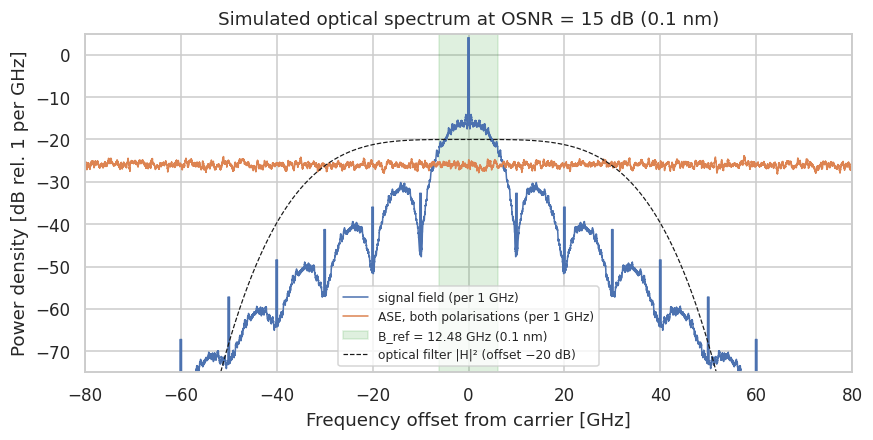

In [11]:
# 3) Optical spectrum: modulated signal vs. ASE (OSNR = 15 dB), averaged periodogram
d = simulate_link(15, 0, 11, SIM_CFG, return_all=True)
n = d["ex"].size
f = np.fft.fftshift(np.fft.fftfreq(n, 1 / SIM_CFG.fs)) / 1e9
def psd_db(x):
    # power per 1-GHz-equivalent bin, smoothed for readability
    p = np.fft.fftshift(np.abs(np.fft.fft(x)) ** 2) / n ** 2 / (SIM_CFG.fs / n / 1e9)
    k = np.ones(31) / 31
    return 10 * np.log10(np.convolve(p, k, mode="same") + 1e-20)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(f, psd_db(d["e_cd"]), lw=1, label="signal field (per 1 GHz)")
ase_total = np.abs(np.fft.fft(d["ex"] - d["e_cd"])) ** 2 + np.abs(np.fft.fft(d["ey"])) ** 2
ax.plot(f, 10 * np.log10(np.convolve(np.fft.fftshift(ase_total) / n ** 2 / (SIM_CFG.fs / n / 1e9), np.ones(31) / 31, "same")),
        lw=1, label="ASE, both polarisations (per 1 GHz)")
bref = SIM_CFG.osnr_ref_bw_hz / 1e9
ax.axvspan(-bref / 2, bref / 2, color="tab:green", alpha=0.15, label=f"B_ref = {bref:.2f} GHz (0.1 nm)")
h_o = np.fft.fftshift(optical_filter(n, SIM_CFG))
ax.plot(f, 20 * np.log10(h_o + 1e-12) - 20, "k--", lw=0.8, label="optical filter |H|² (offset −20 dB)")
ax.set_xlim(-80, 80); ax.set_ylim(-75, 5)
ax.set_xlabel("Frequency offset from carrier [GHz]"); ax.set_ylabel("Power density [dB rel. 1 per GHz]")
ax.set_title("Simulated optical spectrum at OSNR = 15 dB (0.1 nm)")
ax.legend(fontsize=8, loc="lower center")
savefig("optical_spectrum"); plt.show()

The NRZ spectrum has a strong carrier and a main lobe of width ≈ $R_b$; the ASE is flat (white) across the simulation bandwidth.
The OSNR is the ratio between the total signal power and the ASE power inside the green 12.48 GHz band.

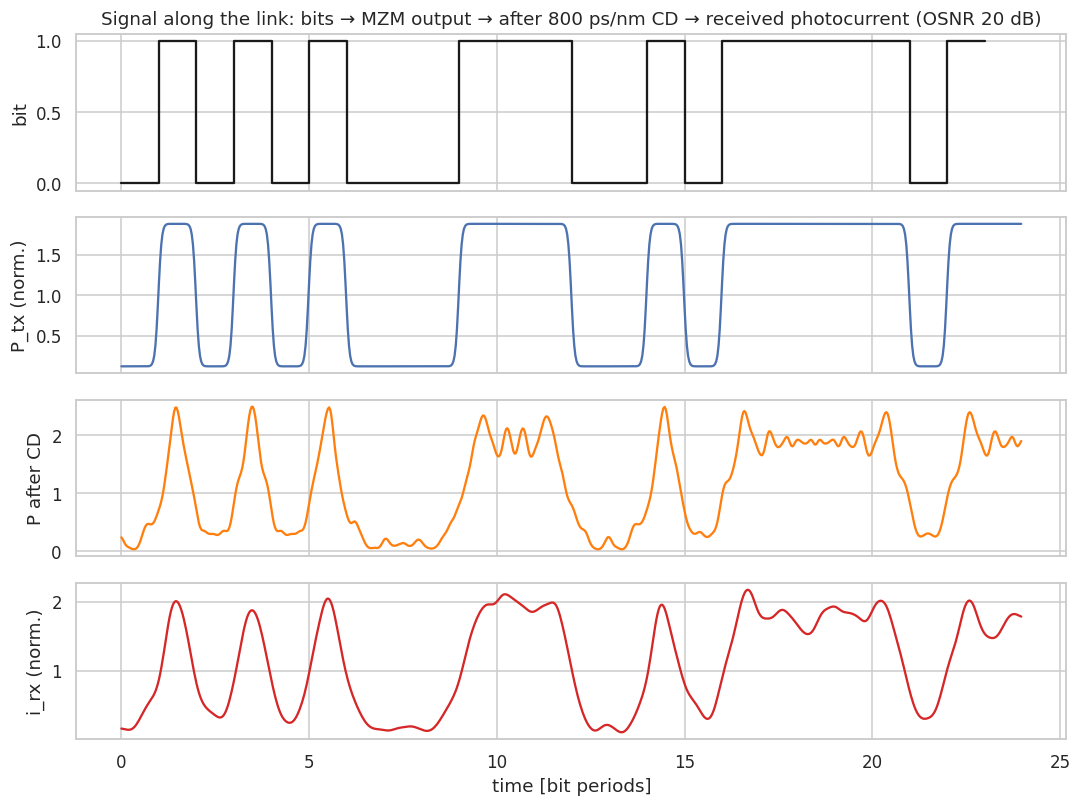

In [12]:
# 4) Waveforms through the link (first 24 bits), OSNR = 20 dB, CD = 800 ps/nm
d = simulate_link(20, 800, 21, SIM_CFG, return_all=True)
nb = 24; ns = nb * SIM_CFG.samples_per_bit
t = np.arange(ns) / SIM_CFG.samples_per_bit
fig, axs = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
axs[0].step(np.arange(nb), d["bits"][:nb], where="post", color="k"); axs[0].set_ylabel("bit")
axs[1].plot(t, np.abs(d["e_tx"][:ns]) ** 2); axs[1].set_ylabel("P_tx (norm.)")
axs[2].plot(t, np.abs(d["e_cd"][:ns]) ** 2, color="tab:orange"); axs[2].set_ylabel("P after CD")
axs[3].plot(t, d["i_rx"][:ns], color="tab:red"); axs[3].set_ylabel("i_rx (norm.)")
axs[3].set_xlabel("time [bit periods]")
axs[0].set_title("Signal along the link: bits → MZM output → after 800 ps/nm CD → received photocurrent (OSNR 20 dB)")
plt.tight_layout(); savefig("link_waveforms"); plt.show()

The transmitted power is a smooth NRZ waveform. After 800 ps/nm the **optical power** shows overshoots and ringing at
transitions (phase‑to‑intensity conversion), and the received photocurrent additionally carries ASE beat noise that is clearly
stronger on the "1" level than on the "0" level.

## 10. Eye‑Diagram Generation

**Rendering.** The waveform is band‑limited interpolated (×8) and cut into 2‑UI traces centred on each bit centre (ideal clock).
Instead of drawing lines with Matplotlib (slow and anti‑aliasing‑dependent), we compute a **2‑D histogram** of all trace samples —
exactly what a sampling oscilloscope does in persistence/colour‑grade mode:

* horizontal axis: 128 bins over 2 UI; vertical axis: 128 bins over a **fixed** normalised amplitude range [−0.3, 3.4]
  (wide enough to contain the noise excursions at 10 dB OSNR);
* hit counts are log‑compressed $\log(1+h)$ and scaled to 0–255 (grayscale PNG); high amplitude is at the top;
* the image contains **no axes, text, labels or colour bars**, so the label cannot leak into the image.

The fixed amplitude window plus the AGC normalisation means that every eye is drawn on the same scale, so the level of the rails
is physically meaningful to the CNN.

In [13]:
def eye_traces(waveform: np.ndarray, cfg: SimConfig) -> tuple[np.ndarray, np.ndarray]:
    """Cut the (ideally clocked) waveform into eye_ui-wide traces centred on the bit centres.
    Returns (t_ui, traces) where traces has shape (n_traces, points_per_trace)."""
    up = cfg.eye_upsample
    wf = sps_signal.resample_poly(waveform, up, 1) if up > 1 else waveform
    spb = cfg.samples_per_bit * up                       # samples per bit after upsampling
    span = int(round(cfg.eye_ui * spb))
    # bit k occupies [k*T, (k+1)*T); its centre is at (k+0.5)*T. Window = centre -/+ eye_ui/2.
    starts = (np.arange(cfg.guard_bits, cfg.n_bits - cfg.guard_bits) + 0.5) * spb - span / 2
    starts = starts.astype(int)
    idx = starts[:, None] + np.arange(span)[None, :]
    t_ui = np.arange(span) / spb
    return t_ui, wf[idx]

def render_eye(waveform: np.ndarray, cfg: SimConfig) -> np.ndarray:
    """Persistence-style eye diagram: 2-D histogram of trace samples, log-compressed, 8-bit.
    Rows = amplitude (top = high), columns = time. Contains NO text, axes or labels."""
    _, tr = eye_traces(waveform, cfg)
    n_tr, span = tr.shape
    s = cfg.img_size
    col = (np.arange(span) * s // span)[None, :].repeat(n_tr, 0)
    row = np.floor((tr - cfg.y_min) / (cfg.y_max - cfg.y_min) * s).astype(int)
    row = np.clip(row, 0, s - 1)                          # out-of-range samples pile on the border
    hist = np.bincount((row * s + col).ravel(), minlength=s * s).reshape(s, s)
    hist = hist[::-1, :]                                  # flip so that high amplitude is at the top
    img = np.log1p(hist.astype(np.float64))
    img = img / img.max() if img.max() > 0 else img
    return (img * 255).round().astype(np.uint8)

def eye_q_factor(waveform: np.ndarray, bits: np.ndarray, cfg: SimConfig) -> float:
    """Q-factor at the eye centre using the known transmitted bits: Q = (mu1-mu0)/(s1+s0)."""
    spb = cfg.samples_per_bit
    k = np.arange(cfg.guard_bits, cfg.n_bits - cfg.guard_bits)
    samples = waveform[(k * spb + spb // 2)]
    b = bits[k]
    m1, m0 = samples[b == 1].mean(), samples[b == 0].mean()
    s1, s0 = samples[b == 1].std(), samples[b == 0].std()
    return float((m1 - m0) / (s1 + s0))

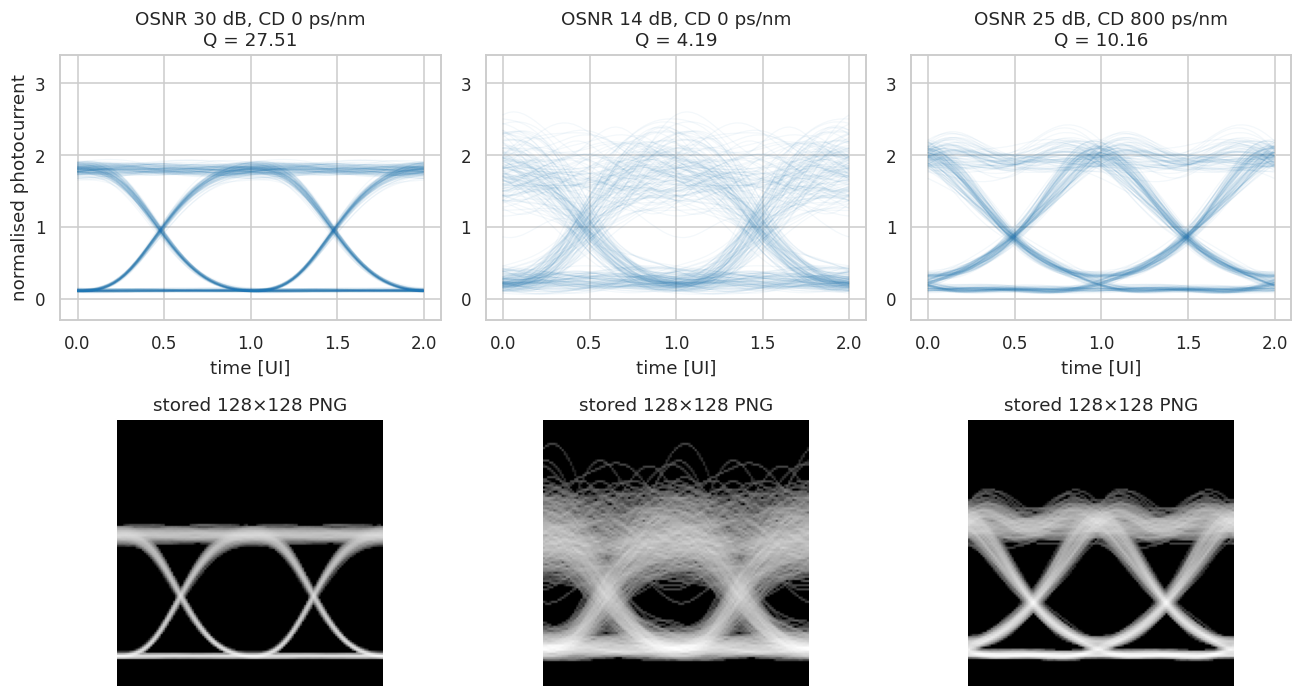

In [14]:
# Classic line eye (Matplotlib) vs. the persistence-histogram image that is stored in the dataset
fig, axs = plt.subplots(2, 3, figsize=(12, 6.5))
for j, (osnr, cd) in enumerate([(30, 0), (14, 0), (25, 800)]):
    wf, bits = simulate_link(osnr, cd, 31 + j, SIM_CFG)
    t_ui, tr = eye_traces(wf, SIM_CFG)
    axs[0, j].plot(t_ui, tr[:300].T, color="tab:blue", alpha=0.05, lw=0.8)
    axs[0, j].set_ylim(SIM_CFG.y_min, SIM_CFG.y_max); axs[0, j].set_xlabel("time [UI]")
    axs[0, j].set_title(f"OSNR {osnr} dB, CD {cd} ps/nm\nQ = {eye_q_factor(wf, bits, SIM_CFG):.2f}")
    axs[1, j].imshow(render_eye(wf, SIM_CFG), cmap="gray", vmin=0, vmax=255)
    axs[1, j].set_title("stored 128×128 PNG"); axs[1, j].axis("off")
axs[0, 0].set_ylabel("normalised photocurrent")
plt.tight_layout(); savefig("eye_line_vs_histogram"); plt.show()

**Physics check of the impairment thresholds.** The impairment classes (Section 11) need physically meaningful thresholds, so we
measure them in *our* simulated system instead of assuming textbook values:

* **Q‑factor / BER vs OSNR** for each dispersion value, with the Gaussian approximation $\mathrm{BER}=\tfrac12\mathrm{erfc}(Q/\sqrt2)$,
  and the back‑to‑back OSNR required for $Q = 6$ (BER ≈ 10⁻⁹);
* the **CD‑induced OSNR penalty**: the extra OSNR needed to reach $Q = 6$ at a given accumulated dispersion,
  $\Delta\mathrm{OSNR}(D_\text{acc}) = \mathrm{OSNR}_\text{req}(D_\text{acc}) - \mathrm{OSNR}_\text{req}(0)$. This is the standard way
  of specifying a transceiver's dispersion tolerance (e.g. "1 dB penalty at ±x ps/nm").

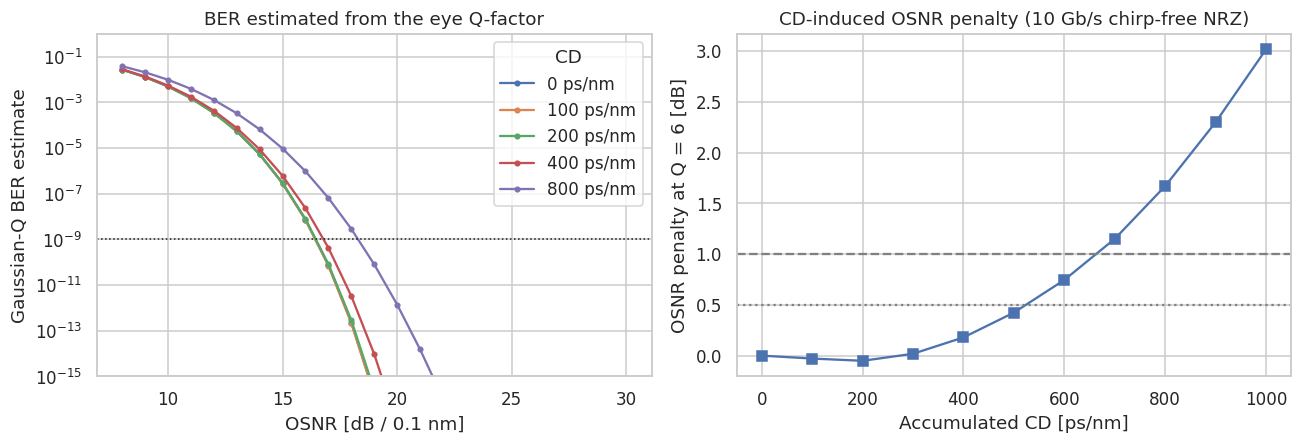

Back-to-back OSNR required for Q = 6 (BER ~1e-9): 16.45 dB (0.1 nm)


CD_ps_nm,0,100,200,300,400,500,600,700,800,900,1000
required_OSNR_dB,16.45,16.42,16.40,16.47,16.63,16.88,17.20,17.60,18.12,18.75,19.47
OSNR_penalty_dB,0.00,-0.03,-0.05,0.02,0.18,0.42,0.75,1.15,1.67,2.30,3.02


In [15]:
cd_levels_phys = [0, 100, 200, 400, 800]
osnr_axis = np.arange(8, 31, 1.0)
q_tab = {cd: [np.mean([eye_q_factor(*simulate_link(o, cd, 500 + s, SIM_CFG), SIM_CFG) for s in range(3)]) for o in osnr_axis]
         for cd in cd_levels_phys}

# Required OSNR for Q = 6 as a function of CD (longer records for a smoother estimate)
pen_cfg = SimConfig(**{**asdict(SIM_CFG), "n_bits": 2048})
osnr_fine = np.arange(12, 26.01, 0.5)

def required_osnr(cd, q_target=6.0, n_seeds=3):
    q = np.array([np.mean([eye_q_factor(*simulate_link(o, cd, 700 + s, pen_cfg), pen_cfg) for s in range(n_seeds)])
                  for o in osnr_fine])
    q = np.maximum.accumulate(q)                    # enforce monotonicity against small statistical wiggles
    return float(np.interp(q_target, q, osnr_fine)) if q.max() >= q_target else float("nan")

cd_axis = np.arange(0, 1001, 100)
req_osnr = np.array([required_osnr(c) for c in cd_axis])
osnr_penalty = req_osnr - req_osnr[0]
req_osnr_q6 = float(req_osnr[0])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for cd in cd_levels_phys:
    axs[0].semilogy(osnr_axis, 0.5 * erfc(np.array(q_tab[cd]) / np.sqrt(2)), "o-", ms=3, label=f"{cd} ps/nm")
axs[0].axhline(1e-9, color="k", ls=":", lw=1); axs[0].set_ylim(1e-15, 1)
axs[0].set_xlabel("OSNR [dB / 0.1 nm]"); axs[0].set_ylabel("Gaussian-Q BER estimate"); axs[0].legend(title="CD")
axs[0].set_title("BER estimated from the eye Q-factor")
axs[1].plot(cd_axis, osnr_penalty, "s-"); axs[1].axhline(0.5, color="gray", ls=":"); axs[1].axhline(1.0, color="gray", ls="--")
axs[1].set_xlabel("Accumulated CD [ps/nm]"); axs[1].set_ylabel("OSNR penalty at Q = 6 [dB]")
axs[1].set_title("CD-induced OSNR penalty (10 Gb/s chirp-free NRZ)")
plt.tight_layout(); savefig("physics_ber_and_cd_penalty"); plt.show()

print(f"Back-to-back OSNR required for Q = 6 (BER ~1e-9): {req_osnr_q6:.2f} dB (0.1 nm)")
display(pd.DataFrame({"CD_ps_nm": cd_axis, "required_OSNR_dB": req_osnr.round(2), "OSNR_penalty_dB": osnr_penalty.round(2)}).set_index("CD_ps_nm").T)

**Interpretation.** The BER curves move to the right as dispersion increases — more OSNR is needed for the same BER, the classic
*OSNR penalty* of chromatic dispersion. For a chirp‑free 10 Gb/s NRZ signal the penalty is negligible up to ≈ 300 ps/nm, a fraction
of a dB at 400 ps/nm, and grows quickly beyond ≈ 500 ps/nm (≈ 1.5–2 dB at 800 ps/nm in our validation runs; the exact values are
printed above). Note also that the required back‑to‑back OSNR (≈ 16–17 dB) is higher than the ≈ 11–13 dB often quoted for ideal
receivers, because of the finite 12 dB extinction ratio, the 50 GHz optical filter (ASE–ASE beating) and the non‑matched 0.75·R_b
receiver. These measurements are the physical basis for the class thresholds chosen in the next section.

## 11. Synthetic Dataset Creation

### 11.1 Parameter grid

* OSNR: 10 → 30 dB in 1 dB steps (21 levels) — `OSNR_MIN_DB`, `OSNR_MAX_DB`, `OSNR_STEP_DB`;
* CD: 0, 100, 200, 400, 800 ps/nm — `CD_LEVELS_PS_NM`;
* `N_REALIZATIONS` = 50 independent realisations per combination → 21 × 5 × 50 = **5 250 images**
  (increase to 100 for 10 500 images; generation time scales linearly).

Each realisation receives a **unique seed** (`BASE_SEED + index`), so it has its own random bits *and* its own ASE noise — no
two images are copies or perturbed versions of each other.

### 11.2 Impairment classes (physical definitions)

| Class | Rule | Physical meaning |
|---|---|---|
| `clean` | OSNR ≥ 20 dB **and** CD < 500 ps/nm | Comfortable OSNR margin and negligible ISI |
| `noise_impaired` | OSNR < 20 dB **and** CD < 500 ps/nm | ASE‑limited: OSNR margin is small or negative |
| `dispersion_impaired` | OSNR ≥ 20 dB **and** CD ≥ 500 ps/nm | ISI‑limited: significant CD‑induced OSNR penalty |
| `noise_and_dispersion` | OSNR < 20 dB **and** CD ≥ 500 ps/nm | Both mechanisms present |

* **OSNR threshold 20 dB**: ≈ 3–4 dB above the back‑to‑back OSNR required for Q = 6 (BER ≈ 10⁻⁹) measured in Section 10. Practical
  systems reserve a few dB of OSNR margin for ageing, PDL, non‑linearities and repairs; a channel below this margin is flagged as
  noise‑impaired.
* **CD threshold 500 ps/nm**: the CD‑induced OSNR penalty measured in Section 10 reaches ≈ 0.5 dB around this value (small at
  400 ps/nm, well above 1 dB at 800 ps/nm). It also coincides with the conservative $R_b\sqrt{|\beta_2|L}\le 1/4$ limit
  (≈ 490 ps/nm at 10 Gb/s). On the training grid {0, 100, 200, 400, 800} only 800 ps/nm is dispersion‑impaired; in the off‑grid
  set, 600 ps/nm (unseen value) is dispersion‑impaired while 50/150/300 ps/nm are not.

Both thresholds are configurable (`OSNR_THRESHOLD_DB`, `CD_THRESHOLD_PS_NM`). The class boundary is *sharp* while the physics is
continuous, so samples at OSNR = 19 vs 20 dB look almost identical — some confusion between neighbouring classes is expected and is
analysed in Section 20.

In [16]:
# ----------------------------- dataset configuration -----------------------------
OSNR_MIN_DB, OSNR_MAX_DB, OSNR_STEP_DB = 10.0, 30.0, 1.0
CD_LEVELS_PS_NM = [0, 100, 200, 400, 800]
N_REALIZATIONS = 10 if QUICK_RUN else 50          # 50 -> 5,250 images; 100 -> 10,500 images
BASE_SEED = 20_240_000

OSNR_THRESHOLD_DB = 20.0
CD_THRESHOLD_PS_NM = 500.0

# Off-grid generalisation set: continuous OSNR and CD values that never occur in training
N_OFFGRID = 60 if QUICK_RUN else 600
OFFGRID_CD_LEVELS = [50, 150, 300, 600]
OFFGRID_BASE_SEED = 90_000_000                   # disjoint seed range

def impairment_label(osnr_db: float, cd_ps_nm: float, osnr_thr_db: float = 20.0, cd_thr_ps_nm: float = 500.0) -> str:
    noisy = osnr_db < osnr_thr_db
    dispersive = abs(cd_ps_nm) >= cd_thr_ps_nm
    if noisy and dispersive:
        return "noise_and_dispersion"
    if noisy:
        return "noise_impaired"
    if dispersive:
        return "dispersion_impaired"
    return "clean"


IMPAIRMENT_CLASSES = ["clean", "noise_impaired", "dispersion_impaired", "noise_and_dispersion"]
CLASS_TO_INDEX = {c: i for i, c in enumerate(IMPAIRMENT_CLASSES)}

OSNR_GRID = np.round(np.arange(OSNR_MIN_DB, OSNR_MAX_DB + 1e-9, OSNR_STEP_DB), 3)
print(f"{len(OSNR_GRID)} OSNR levels x {len(CD_LEVELS_PS_NM)} CD levels x {N_REALIZATIONS} realisations "
      f"= {len(OSNR_GRID) * len(CD_LEVELS_PS_NM) * N_REALIZATIONS} images")
print(f"OSNR threshold margin over the Q = 6 requirement: {OSNR_THRESHOLD_DB - req_osnr_q6:.1f} dB")
print(f"Measured CD-induced OSNR penalty at the CD threshold: {np.interp(CD_THRESHOLD_PS_NM, cd_axis, osnr_penalty):.2f} dB")

21 OSNR levels x 5 CD levels x 50 realisations = 5250 images
OSNR threshold margin over the Q = 6 requirement: 3.5 dB
Measured CD-induced OSNR penalty at the CD threshold: 0.42 dB


### 11.3 Generation

The generator builds the metadata table first, then simulates and renders every image in parallel (joblib, all CPU cores),
writing `eye_XXXXX.png`, `metadata.csv` and `dataset_information.txt`. If a complete dataset already exists locally — or a zipped
copy exists on Google Drive from an earlier session — it is reused instead of regenerated. A sequential fallback is used if
parallel execution is unavailable.

In [17]:
from joblib import Parallel, delayed

def _render_one(osnr_db, cd_ps_nm, seed, out_path, cfg):
    # Simulate one realisation and write its eye diagram as an 8-bit grayscale PNG.
    wf, _ = simulate_link(float(osnr_db), float(cd_ps_nm), int(seed), cfg)
    Image.fromarray(render_eye(wf, cfg)).save(out_path, optimize=True)
    return True

def build_dataset(root: Path, meta: pd.DataFrame, cfg: SimConfig, description: str):
    # Generate (or reuse) a dataset folder described by `meta`.
    img_dir = root / "eye_diagrams"
    meta_path = root / "metadata.csv"
    zip_on_drive = OUTPUT_DIR / f"{root.name}.zip"
    if meta_path.exists() and len(list(img_dir.glob("*.png"))) == len(meta):
        print(f"[reuse] {root} already contains {len(meta)} images."); return pd.read_csv(meta_path)
    if zip_on_drive.exists():
        print(f"[restore] unzipping {zip_on_drive} ...")
        with zipfile.ZipFile(zip_on_drive) as zf:
            zf.extractall(root.parent)
        if meta_path.exists() and len(list(img_dir.glob("*.png"))) == len(meta):
            return pd.read_csv(meta_path)
        print("[restore] archive incomplete or outdated - regenerating.")
    img_dir.mkdir(parents=True, exist_ok=True)
    jobs = [(r.OSNR_dB, r.chromatic_dispersion_ps_nm, r.simulation_seed, str(img_dir / r.image_filename))
            for r in meta.itertuples()]
    t0 = time.time()
    try:
        Parallel(n_jobs=-1, batch_size=32)(delayed(_render_one)(*j, cfg) for j in jobs)
    except Exception as exc:
        print("Parallel generation failed (", repr(exc), ") - falling back to sequential mode.")
        for k, j in enumerate(jobs):
            _render_one(*j, cfg)
            if k % 500 == 0:
                print(f"  {k}/{len(jobs)}")
    print(f"Generated {len(jobs)} images in {time.time() - t0:.1f} s")
    meta.to_csv(meta_path, index=False)
    with open(root / "dataset_information.txt", "w") as fh:
        fh.write(description + "\n\nSIMULATED DATA - NOT LABORATORY MEASUREMENTS\n\n")
        fh.write("Simulation configuration:\n")
        for k, v in asdict(cfg).items():
            fh.write(f"  {k}: {v}\n")
        fh.write(f"  OSNR reference bandwidth: {cfg.osnr_ref_bw_hz/1e9:.4f} GHz ({cfg.osnr_ref_bw_nm} nm)\n")
        fh.write(f"Impairment thresholds: OSNR < {OSNR_THRESHOLD_DB} dB -> noise; |CD| >= {CD_THRESHOLD_PS_NM} ps/nm -> dispersion\n")
        fh.write(f"Number of images: {len(meta)}\n")
    # zipped backup on Drive (stored without recompression: PNGs are already compressed)
    try:
        shutil.make_archive(str(OUTPUT_DIR / root.name), "zip", root_dir=root.parent, base_dir=root.name)
        print("Backup written to", zip_on_drive)
    except Exception as exc:
        print("Could not write dataset backup:", repr(exc))
    return meta

# ----------------------------- main grid metadata -----------------------------
rows, idx = [], 0
for cd in CD_LEVELS_PS_NM:
    for osnr in OSNR_GRID:
        for r in range(N_REALIZATIONS):
            idx += 1
            rows.append(dict(image_filename=f"eye_{idx:05d}.png", OSNR_dB=float(osnr),
                             chromatic_dispersion_ps_nm=float(cd), simulation_seed=BASE_SEED + idx,
                             impairment_type=impairment_label(osnr, cd, OSNR_THRESHOLD_DB, CD_THRESHOLD_PS_NM),
                             realization=r, combo_id=f"osnr{osnr:g}_cd{cd:g}"))
meta_main = pd.DataFrame(rows)
meta_main = build_dataset(DATA_ROOT, meta_main, SIM_CFG,
                          "Main grid dataset: NRZ-OOK 10 Gb/s eye diagrams on an OSNR x CD grid.")

# ----------------------------- off-grid metadata -----------------------------
rng_off = np.random.default_rng(GLOBAL_SEED)
off_rows = []
for i in range(N_OFFGRID):
    osnr = float(np.round(rng_off.uniform(OSNR_MIN_DB, OSNR_MAX_DB), 2))
    cd = float(rng_off.choice(OFFGRID_CD_LEVELS))
    off_rows.append(dict(image_filename=f"eye_off_{i + 1:05d}.png", OSNR_dB=osnr, chromatic_dispersion_ps_nm=cd,
                         simulation_seed=OFFGRID_BASE_SEED + i + 1,
                         impairment_type=impairment_label(osnr, cd, OSNR_THRESHOLD_DB, CD_THRESHOLD_PS_NM),
                         realization=0, combo_id="offgrid"))
meta_off = pd.DataFrame(off_rows)
meta_off = build_dataset(OFFGRID_ROOT, meta_off, SIM_CFG,
                         "Off-grid test set: continuous OSNR in [10, 30] dB and CD values unseen in training.")
print("Main dataset:", len(meta_main), "images | Off-grid set:", len(meta_off), "images")

Generated 5250 images in 194.0 s
Backup written to /content/drive/MyDrive/OSNR_Eye_Project/OSNR_Dataset.zip
Generated 600 images in 17.6 s
Backup written to /content/drive/MyDrive/OSNR_Eye_Project/OSNR_Dataset_offgrid.zip
Main dataset: 5250 images | Off-grid set: 600 images


## 12. Dataset Inspection

We verify the integrity of the generated dataset: metadata schema, missing values, image size/type, seed uniqueness and
**exact‑duplicate detection by MD5 hash** of the PNG pixel data (a direct test that no two samples are identical).

In [18]:
display(meta_main.head(8))
print(meta_main.dtypes.to_string())
print("\nMissing values per column:\n", meta_main.isna().sum().to_string())

def pixel_md5(path):
    return hashlib.md5(np.asarray(Image.open(path)).tobytes()).hexdigest()

img_dir_main = DATA_ROOT / "eye_diagrams"
first = Image.open(img_dir_main / meta_main.image_filename.iloc[0])
print(f"\nImage mode = {first.mode}, size = {first.size}")
meta_main["md5"] = [pixel_md5(img_dir_main / f) for f in meta_main.image_filename]
meta_off["md5"] = [pixel_md5(OFFGRID_ROOT / "eye_diagrams" / f) for f in meta_off.image_filename]
print("Unique seeds   :", meta_main.simulation_seed.is_unique and meta_off.simulation_seed.is_unique)
print("Duplicate images (identical pixels) in main set:", meta_main.md5.duplicated().sum())
print("Images shared between main and off-grid sets   :", len(set(meta_main.md5) & set(meta_off.md5)))

,image_filename,OSNR_dB,chromatic_dispersion_ps_nm,simulation_seed,impairment_type,realization,combo_id
0,eye_00001.png,10.0,0.0,20240001,noise_impaired,0,osnr10_cd0
1,eye_00002.png,10.0,0.0,20240002,noise_impaired,1,osnr10_cd0
2,eye_00003.png,10.0,0.0,20240003,noise_impaired,2,osnr10_cd0
3,eye_00004.png,10.0,0.0,20240004,noise_impaired,3,osnr10_cd0
4,eye_00005.png,10.0,0.0,20240005,noise_impaired,4,osnr10_cd0
5,eye_00006.png,10.0,0.0,20240006,noise_impaired,5,osnr10_cd0
6,eye_00007.png,10.0,0.0,20240007,noise_impaired,6,osnr10_cd0
7,eye_00008.png,10.0,0.0,20240008,noise_impaired,7,osnr10_cd0


image_filename                 object
OSNR_dB                       float64
chromatic_dispersion_ps_nm    float64
simulation_seed                 int64
impairment_type                object
realization                     int64
combo_id                       object

Missing values per column:
 image_filename                0
OSNR_dB                       0
chromatic_dispersion_ps_nm    0
simulation_seed               0
impairment_type               0
realization                   0
combo_id                      0

Image mode = L, size = (128, 128)
Unique seeds   : True
Duplicate images (identical pixels) in main set: 0
Images shared between main and off-grid sets   : 0


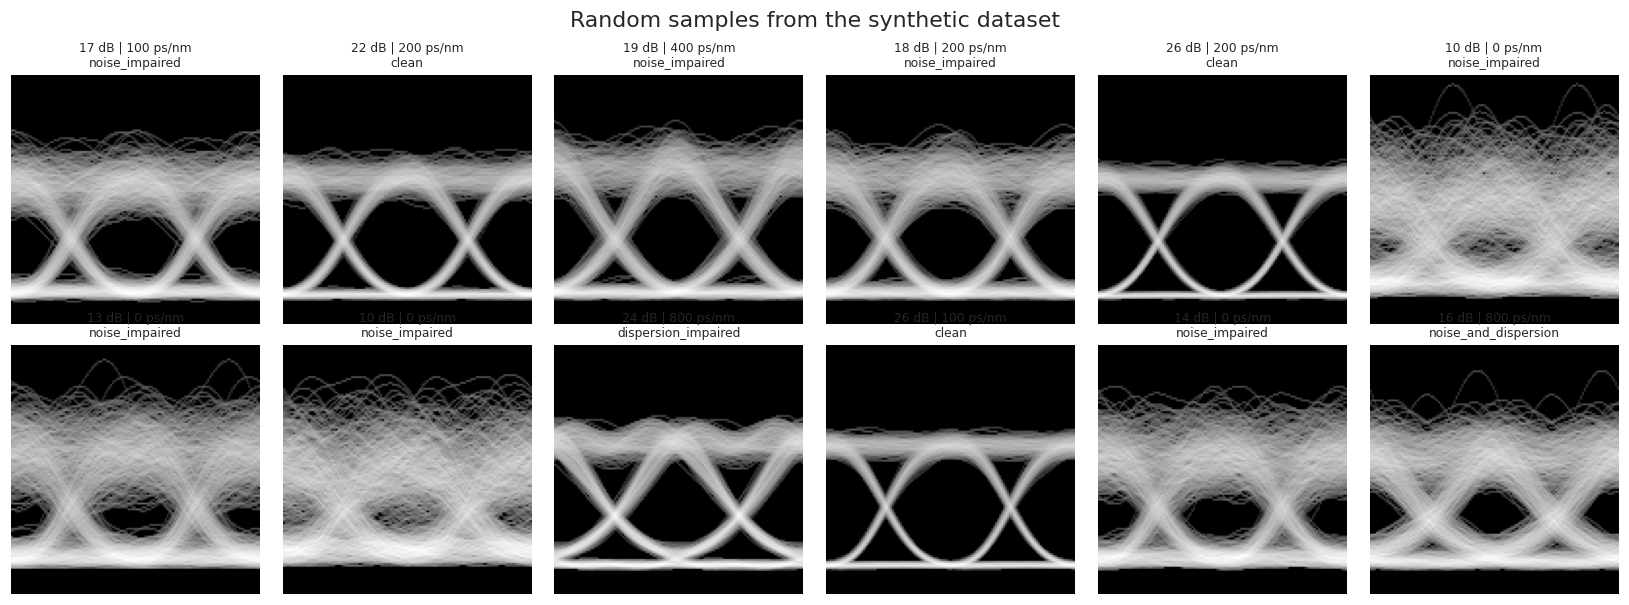

In [19]:
# Random sample of 12 eye diagrams with their labels (labels are shown only in the plot titles, never in the images)
sample = meta_main.sample(12, random_state=GLOBAL_SEED)
fig, axs = plt.subplots(2, 6, figsize=(15, 5.6))
for ax, r in zip(axs.ravel(), sample.itertuples()):
    ax.imshow(Image.open(img_dir_main / r.image_filename), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{r.OSNR_dB:g} dB | {r.chromatic_dispersion_ps_nm:g} ps/nm\n{r.impairment_type}", fontsize=8)
    ax.axis("off")
plt.suptitle("Random samples from the synthetic dataset"); plt.tight_layout(); savefig("random_samples"); plt.show()

## 13. Exploratory Data Analysis

### 13.1 Dataset size and label distributions

Main dataset : 5250 images, 105 OSNR/CD combinations
Off-grid set : 600 images
Disk size of PNGs: 20.0 MB (mean 3.8 kB per image)


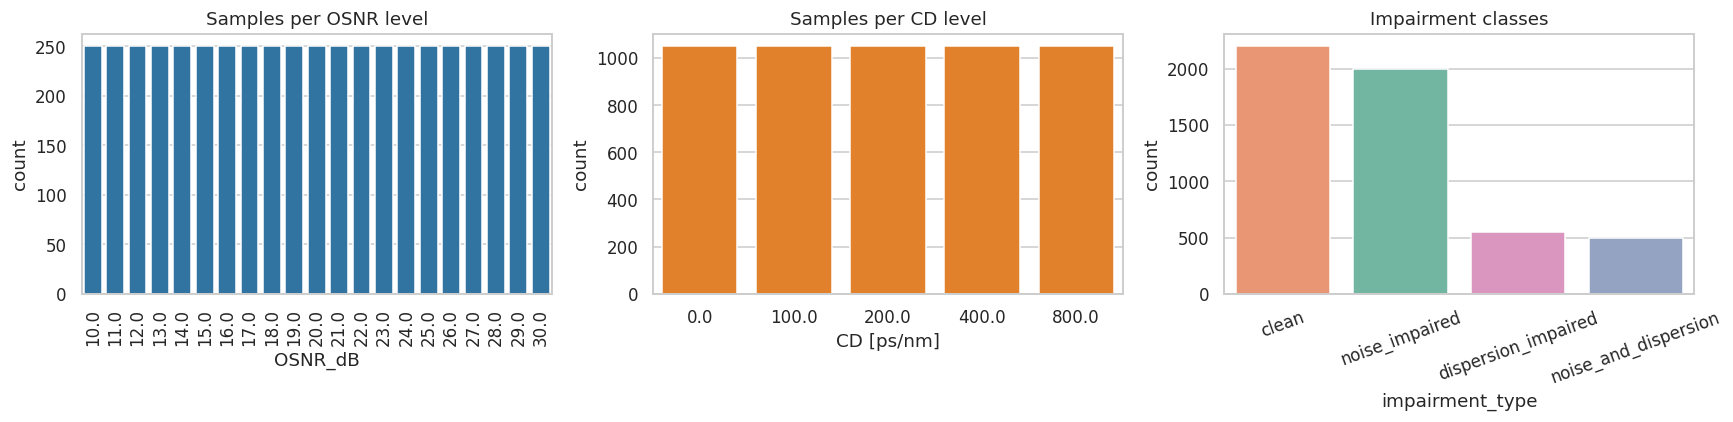

                      count  fraction
impairment_type                      
clean                  2200     0.419
noise_impaired         2000     0.381
dispersion_impaired     550     0.105
noise_and_dispersion    500     0.095


In [20]:
print(f"Main dataset : {len(meta_main)} images, {meta_main.combo_id.nunique()} OSNR/CD combinations")
print(f"Off-grid set : {len(meta_off)} images")
size_mb = sum(p.stat().st_size for p in img_dir_main.glob("*.png")) / 1e6
print(f"Disk size of PNGs: {size_mb:.1f} MB (mean {1e3 * size_mb / len(meta_main):.1f} kB per image)")

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="OSNR_dB", data=meta_main, ax=axs[0], color="tab:blue")
axs[0].set_title("Samples per OSNR level"); axs[0].tick_params(axis="x", rotation=90)
sns.countplot(x="chromatic_dispersion_ps_nm", data=meta_main, ax=axs[1], color="tab:orange")
axs[1].set_title("Samples per CD level"); axs[1].set_xlabel("CD [ps/nm]")
order = IMPAIRMENT_CLASSES
sns.countplot(x="impairment_type", data=meta_main, order=order, ax=axs[2], palette="Set2", hue="impairment_type", legend=False)
axs[2].set_title("Impairment classes"); axs[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); savefig("eda_counts"); plt.show()

print(meta_main.impairment_type.value_counts().reindex(order).to_frame("count")
      .assign(fraction=lambda d: (d["count"] / d["count"].sum()).round(3)).to_string())

* **OSNR and CD** are perfectly balanced by design (a full factorial grid with the same number of realisations per cell), so the
  regression target has a uniform distribution and no OSNR level is under‑represented.
* **Impairment classes are not balanced**: 11 of the 21 OSNR levels are ≥ 20 dB, but only 1 of the 5 CD levels (800 ps/nm) is
  ≥ 500 ps/nm, so the two dispersion classes together contain only ≈ 20 % of the images. This is a direct consequence of the physical thresholds;
  we therefore report macro‑averaged precision/recall/F1 (each class weighted equally) in Section 20.

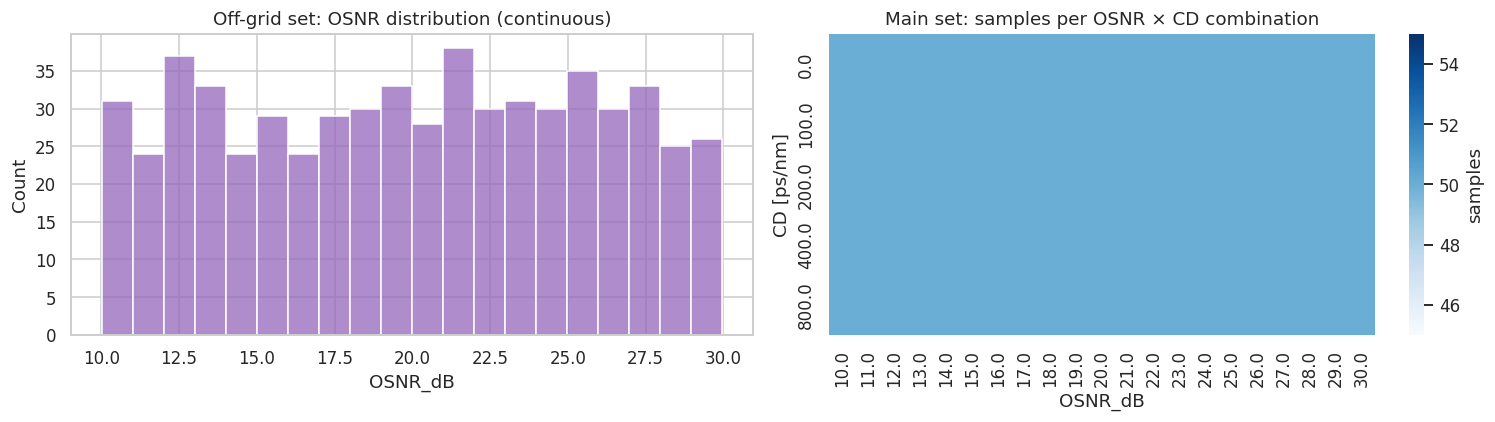

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(meta_off.OSNR_dB, bins=20, ax=axs[0], color="tab:purple")
axs[0].set_title("Off-grid set: OSNR distribution (continuous)")
pivot = meta_main.pivot_table(index="chromatic_dispersion_ps_nm", columns="OSNR_dB", values="image_filename", aggfunc="count")
sns.heatmap(pivot, ax=axs[1], cmap="Blues", cbar_kws={"label": "samples"})
axs[1].set_title("Main set: samples per OSNR × CD combination"); axs[1].set_ylabel("CD [ps/nm]")
plt.tight_layout(); savefig("eda_offgrid_and_grid"); plt.show()

### 13.2 How the eye changes with OSNR and with dispersion

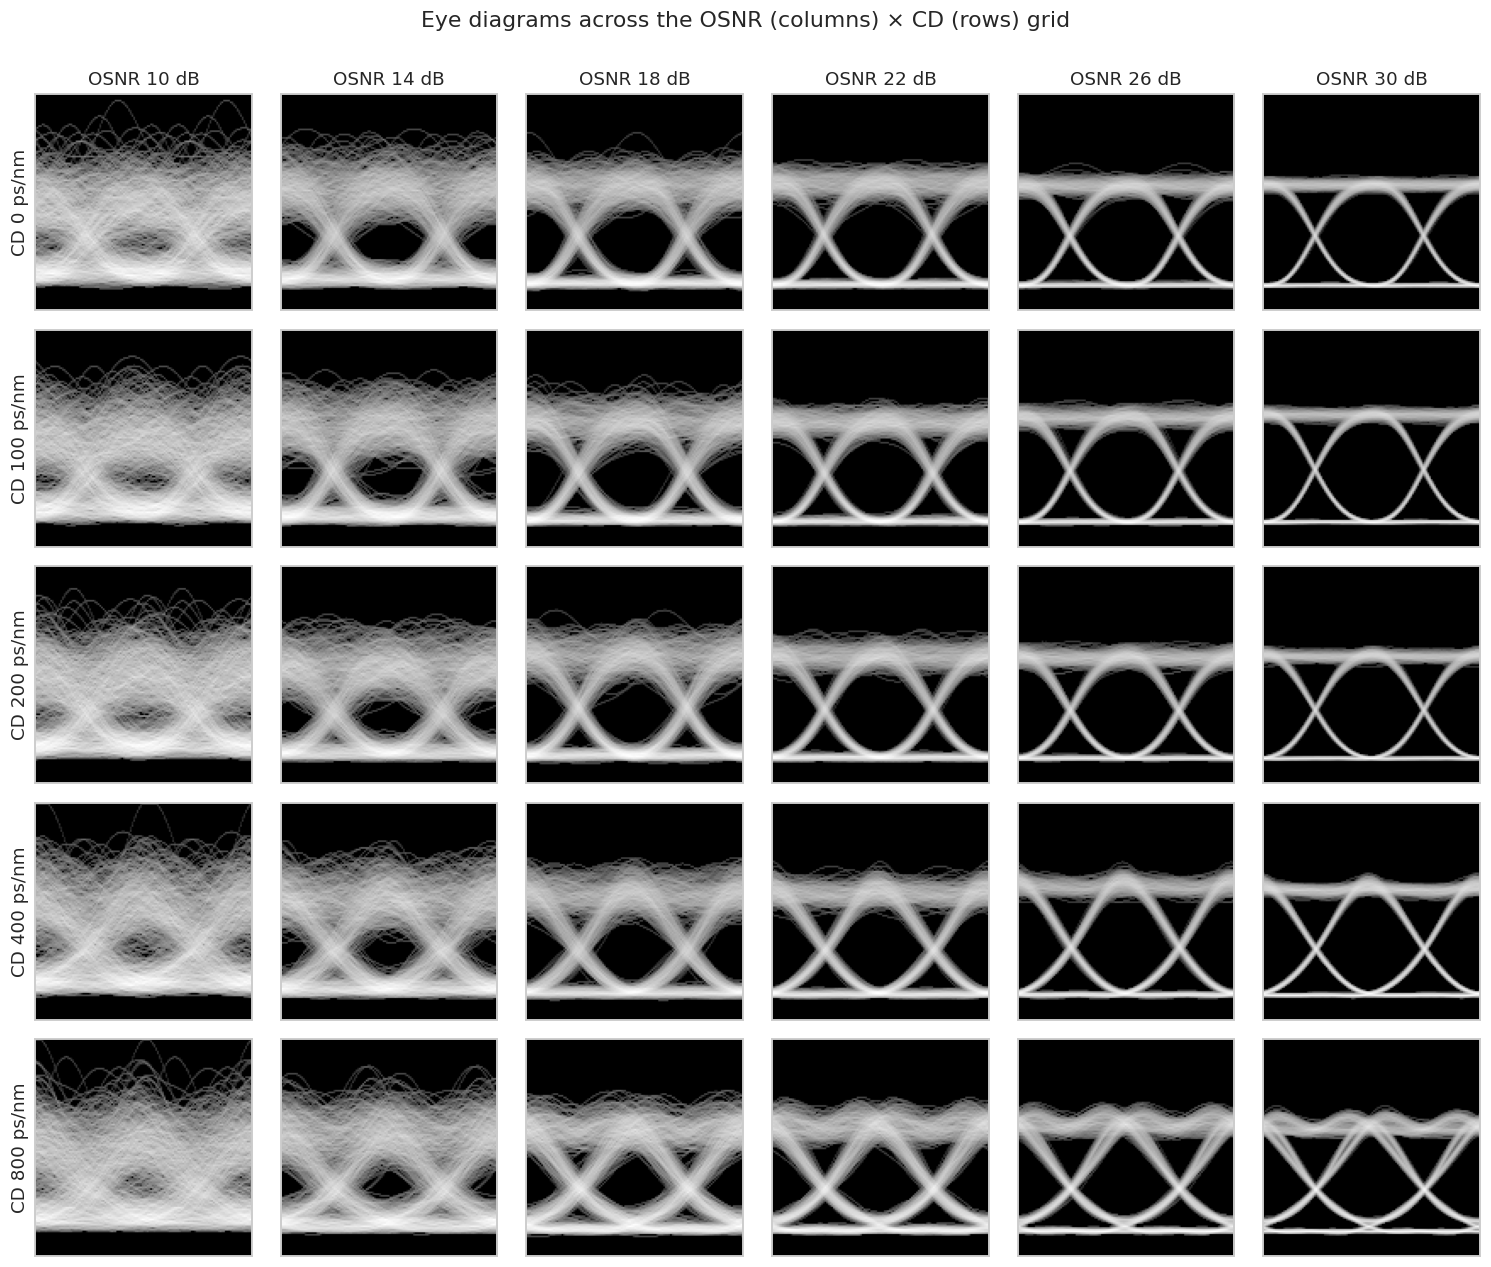

In [22]:
def load_img(name, root=DATA_ROOT):
    return np.asarray(Image.open(root / "eye_diagrams" / name))

osnr_show = [10, 14, 18, 22, 26, 30]
cd_show = CD_LEVELS_PS_NM
fig, axs = plt.subplots(len(cd_show), len(osnr_show), figsize=(2.3 * len(osnr_show), 2.3 * len(cd_show)))
for i, cd in enumerate(cd_show):
    for j, o in enumerate(osnr_show):
        r = meta_main[(meta_main.chromatic_dispersion_ps_nm == cd) & (meta_main.OSNR_dB == o)].iloc[0]
        axs[i, j].imshow(load_img(r.image_filename), cmap="gray", vmin=0, vmax=255)
        axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
        if i == 0: axs[i, j].set_title(f"OSNR {o} dB")
        if j == 0: axs[i, j].set_ylabel(f"CD {cd} ps/nm")
plt.suptitle("Eye diagrams across the OSNR (columns) × CD (rows) grid", y=1.0)
plt.tight_layout(); savefig("eda_grid_osnr_cd"); plt.show()

**Observations (physics):**

* **Along a row (increasing OSNR)** the rails become thinner and the eye opens. At low OSNR the "1" rail is visibly broader than
  the "0" rail (signal–ASE beat noise ∝ signal power) and the "0" rail is lifted by the ASE–ASE DC term.
* **Down a column (increasing CD)** the noise texture stays similar but the eye shape changes deterministically: the rails split
  into several pattern‑dependent traces, overshoots appear above the "1" level, the crossing point moves and the eye closes
  vertically. At 800 ps/nm the ISI is clearly visible even at high OSNR.
* Noise and dispersion therefore leave **different visual signatures** — random broadening versus structured distortion — which
  is what makes joint OSNR regression and impairment classification feasible.

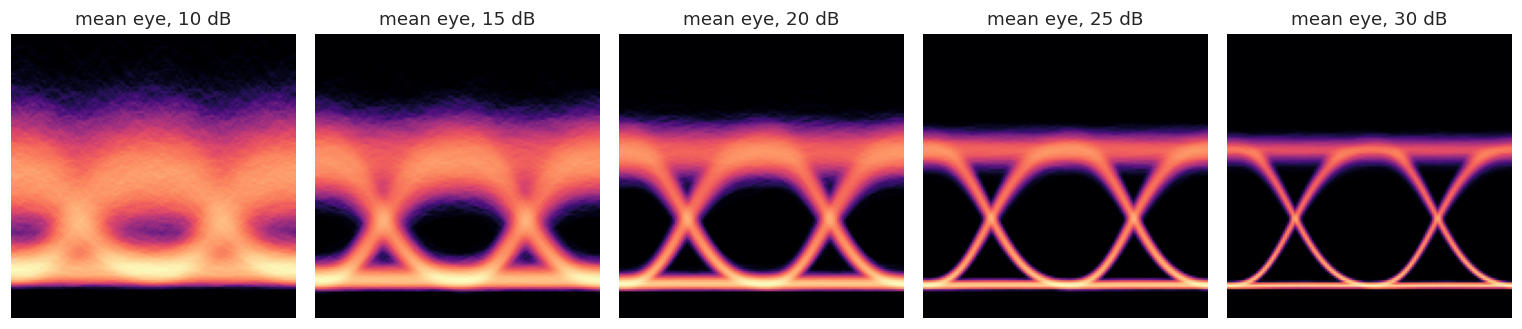

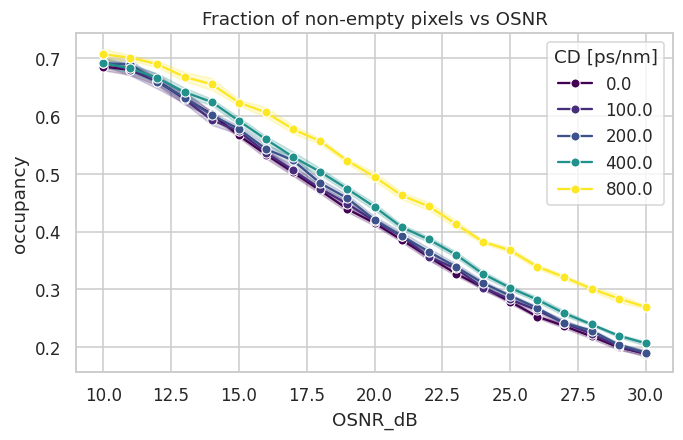

In [23]:
# Mean image per OSNR level (CD = 0) and quantitative trend of a simple image statistic
fig, axs = plt.subplots(1, 5, figsize=(14, 3))
for ax, o in zip(axs, [10, 15, 20, 25, 30]):
    names = meta_main[(meta_main.OSNR_dB == o) & (meta_main.chromatic_dispersion_ps_nm == 0)].image_filename[:20]
    ax.imshow(np.mean([load_img(n) for n in names], axis=0), cmap="magma"); ax.set_title(f"mean eye, {o} dB"); ax.axis("off")
plt.tight_layout(); savefig("eda_mean_eyes"); plt.show()

# Fraction of illuminated pixels (eye "occupancy") vs OSNR for each CD
sub = meta_main.groupby(["chromatic_dispersion_ps_nm", "OSNR_dB"]).head(10).copy()
sub["occupancy"] = [(load_img(n) > 0).mean() for n in sub.image_filename]
plt.figure(figsize=(7, 4))
sns.lineplot(data=sub, x="OSNR_dB", y="occupancy", hue="chromatic_dispersion_ps_nm", marker="o", palette="viridis")
plt.title("Fraction of non-empty pixels vs OSNR"); plt.ylabel("occupancy"); plt.legend(title="CD [ps/nm]")
savefig("eda_occupancy"); plt.show()

The **mean eyes** show the systematic opening of the eye with OSNR. The **occupancy** statistic (fraction of pixels hit by at least
one trace) decreases monotonically with OSNR, but curves for different CD values overlap and flatten above ≈ 22 dB: a single
scalar feature cannot separate OSNR from CD effects at high OSNR. This motivates learning richer features with a CNN.

## 14. Data Preprocessing

* **Resolution 128 × 128.** Images are generated at this size, so no resizing artefacts occur for the dataset; the same function
  still resizes external images (bilinear) so that uploaded eyes go through *exactly* the same pipeline. 128 px over 3.7 normalised
  amplitude units gives ≈ 0.03 units per row — fine enough to resolve rail thickness at 30 dB OSNR.
* **Grayscale (1 channel).** Pixel brightness encodes a single physical quantity (log hit‑count); RGB would triple the input size
  without adding information.
* **Normalisation.** Pixel values are divided by 255 → [0, 1].
* **Labels.** OSNR is kept in dB; the model internally predicts a standardised value $z$ and a fixed output layer converts it back
  to dB ($\hat y = \mu + \sigma z$), so the saved model directly outputs dB. Impairment classes are mapped to integers 0–3.

In [24]:
IMG_SIZE = 128
PREPROCESS_CONFIG = {
    "img_size": IMG_SIZE, "color_mode": "grayscale", "channels": 1,
    "resize_interpolation": "bilinear", "normalisation": "pixel / 255.0 (float32, range [0, 1])",
    "background": "dark (0) background, bright traces; light-background images are inverted",
    "eye_span_UI": SIM_CFG.eye_ui, "amplitude_window_normalised": [SIM_CFG.y_min, SIM_CFG.y_max],
    "amplitude_normalisation": "photocurrent divided by its mean (constant-power receiver)",
    "intensity_mapping": "log(1 + hits) scaled to 0..255",
}

def preprocess_image(path_or_array, img_size: int = IMG_SIZE, verbose: bool = False) -> np.ndarray:
    # Load an eye-diagram image and return a float32 array of shape (img_size, img_size, 1) in [0, 1].
    # Exactly the same function is used for the dataset and for user-uploaded images.
    img = Image.open(path_or_array) if isinstance(path_or_array, (str, Path)) else Image.fromarray(np.asarray(path_or_array))
    img = img.convert("L")                                       # grayscale (handles RGB / RGBA / palette PNGs)
    if img.size != (img_size, img_size):
        img = img.resize((img_size, img_size), Image.BILINEAR)
    x = np.asarray(img, dtype=np.float32) / 255.0
    if x.mean() > 0.5:                                           # light background -> invert to match training data
        if verbose:
            print("Note: light background detected - image inverted to match the training convention.")
        x = 1.0 - x
    return x[..., None]

def load_split_images(meta: pd.DataFrame, root: Path) -> np.ndarray:
    # Load all images of a metadata table as uint8 (N, H, W, 1) to save RAM; scaling to [0,1] happens in tf.data.
    out = np.empty((len(meta), IMG_SIZE, IMG_SIZE, 1), dtype=np.uint8)
    for k, name in enumerate(meta.image_filename):
        out[k] = np.round(preprocess_image(root / "eye_diagrams" / name) * 255).astype(np.uint8)
    return out

t0 = time.time()
X_all = load_split_images(meta_main, DATA_ROOT)
X_off = load_split_images(meta_off, OFFGRID_ROOT)
print(f"Loaded {X_all.shape} + {X_off.shape} uint8 arrays in {time.time() - t0:.1f} s "
      f"({(X_all.nbytes + X_off.nbytes) / 1e6:.0f} MB)")

y_osnr_all = meta_main.OSNR_dB.values.astype(np.float32)
y_cls_all = meta_main.impairment_type.map(CLASS_TO_INDEX).values.astype(np.int32)
y_osnr_off = meta_off.OSNR_dB.values.astype(np.float32)
y_cls_off = meta_off.impairment_type.map(CLASS_TO_INDEX).values.astype(np.int32)

Loaded (5250, 128, 128, 1) + (600, 128, 128, 1) uint8 arrays in 2.2 s (96 MB)


## 15. Training and Validation Split

**Leakage control.** Three precautions are taken:

1. **Independent realisations.** Every image comes from a unique seed (bits *and* noise), the MD5 check in Section 12 confirmed
   that no two images are identical, and no augmentation creates near‑copies — so splitting realisations of the same parameter
   combination does not place "nearly identical versions of the same signal" in different sets.
2. **Held‑out combinations (grouped split).** Two OSNR levels per CD value (10 combinations, interior OSNR values only so the task
   is interpolation) are removed **entirely** — all their realisations — before splitting. They form the *unseen‑combination* test
   set and are never used for training, validation, early stopping or model selection.
3. **Stratified 70/15/15 split** of the remaining combinations, stratified by OSNR/CD combination, so every seen combination is
   represented proportionally in train, validation and test.

The off‑grid set (continuous OSNR, CD ∈ {50, 150, 300, 600} ps/nm, separate seed range) is a third, completely independent test.

In [25]:
from sklearn.model_selection import train_test_split

rng_split = np.random.default_rng(GLOBAL_SEED)
interior = OSNR_GRID[(OSNR_GRID > OSNR_GRID.min()) & (OSNR_GRID < OSNR_GRID.max())]
held_out_combos = []
for cd in CD_LEVELS_PS_NM:
    for o in rng_split.choice(interior, size=2, replace=False):
        held_out_combos.append(f"osnr{o:g}_cd{cd:g}")
is_unseen = meta_main.combo_id.isin(held_out_combos).values

idx_seen = np.where(~is_unseen)[0]
idx_unseen = np.where(is_unseen)[0]
strat = meta_main.combo_id.values[idx_seen]
idx_train, idx_tmp = train_test_split(idx_seen, test_size=0.30, stratify=strat, random_state=GLOBAL_SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=meta_main.combo_id.values[idx_tmp],
                                     random_state=GLOBAL_SEED)

meta_main["split"] = "train"
meta_main.loc[idx_val, "split"] = "val"
meta_main.loc[idx_test, "split"] = "test"
meta_main.loc[idx_unseen, "split"] = "unseen_combo"
meta_main.drop(columns=["md5"]).to_csv(OUTPUT_DIR / "metadata_with_splits.csv", index=False)

print("Held-out (unseen) combinations:", sorted(held_out_combos))
print(meta_main.split.value_counts().to_string())

# ---- leakage checks ----
sets = {s: set(meta_main.loc[meta_main.split == s, "md5"]) for s in ["train", "val", "test", "unseen_combo"]}
for a in sets:
    for b in sets:
        if a < b:
            assert not (sets[a] & sets[b]), f"identical image shared by {a} and {b}"
train_combos = set(meta_main.loc[meta_main.split == "train", "combo_id"])
assert not (train_combos & set(held_out_combos)), "held-out combination leaked into training"
assert not (set(meta_main.simulation_seed) & set(meta_off.simulation_seed)), "seed overlap with off-grid set"
print("Leakage checks passed: no identical images across splits, held-out combinations absent from training, disjoint seeds.")

Held-out (unseen) combinations: ['osnr12_cd0', 'osnr12_cd200', 'osnr12_cd400', 'osnr18_cd100', 'osnr19_cd100', 'osnr21_cd400', 'osnr24_cd200', 'osnr24_cd800', 'osnr25_cd0', 'osnr25_cd800']
split
train           3325
test             713
val              712
unseen_combo     500
Leakage checks passed: no identical images across splits, held-out combinations absent from training, disjoint seeds.


In [26]:
OSNR_MEAN = float(y_osnr_all[idx_train].mean())
OSNR_STD = float(y_osnr_all[idx_train].std())
PREPROCESS_CONFIG.update({"osnr_mean_dB": OSNR_MEAN, "osnr_std_dB": OSNR_STD})

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X, y_osnr, y_cls, shuffle=False, batch_size=BATCH_SIZE):
    # tf.data pipeline: uint8 -> float32 [0,1]; targets as a dict matching the model's output names.
    ds = tf.data.Dataset.from_tensor_slices((X, {"osnr": y_osnr, "impairment": y_cls}))
    if shuffle:
        ds = ds.shuffle(len(X), seed=GLOBAL_SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

def subset(idx):
    return X_all[idx], y_osnr_all[idx], y_cls_all[idx]

ds_train = make_ds(*subset(idx_train), shuffle=True)
ds_val = make_ds(*subset(idx_val))
ds_test = make_ds(*subset(idx_test))
ds_unseen = make_ds(*subset(idx_unseen))
ds_off = make_ds(X_off, y_osnr_off, y_cls_off)
print(f"train {len(idx_train)} | val {len(idx_val)} | test {len(idx_test)} | unseen-combo {len(idx_unseen)} | off-grid {len(X_off)}")
print(f"Training OSNR mean = {OSNR_MEAN:.2f} dB, std = {OSNR_STD:.2f} dB")

train 3325 | val 712 | test 713 | unseen-combo 500 | off-grid 600
Training OSNR mean = 20.08 dB, std = 6.13 dB


## 16. CNN Architecture

```
input 128×128×1
 ├─ Conv 3×3 (32)  → [BN] → ReLU → MaxPool 2×2        → 64×64×32
 ├─ Conv 3×3 (64)  → [BN] → ReLU → MaxPool 2×2        → 32×32×64
 ├─ Conv 3×3 (128) → [BN] → ReLU → Conv 3×3 (128) → [BN] → ReLU → MaxPool → 16×16×128
 ├─ Conv 3×3 (128) → [BN] → ReLU → Conv 3×3 (128) → [BN] → ReLU → MaxPool →  8× 8×128
 ├─ Flatten (8192) → Dropout 0.4 → Dense 128 → ReLU → Dropout 0.3      (shared representation)
 ├─ OSNR head:       Dense 1 (linear, z) → fixed affine layer  ŷ = μ + σ z   [dB]
 └─ Impairment head: Dense 4 → softmax
```

* **Convolution** slides small learnable kernels over the image; each output is a weighted sum of a 3×3 neighbourhood, so the same
  detector is applied at every position (translation equivariance, few parameters).
* **What the filters detect.** Early filters respond to local edges and textures — rail edges, the slope of transitions, the
  "fuzziness" of a noisy rail. Deeper filters combine them into structures such as rail thickness, the eye opening, crossings,
  overshoots and multi‑trace ISI patterns.
* **Max pooling** halves the spatial resolution, enlarging the receptive field of later layers and adding robustness to small
  shifts (e.g. slight clock‑phase offsets).
* **ReLU** $\max(0, x)$ introduces non‑linearity cheaply and avoids vanishing gradients of saturating activations.
* **Batch normalisation (BN, optional — `USE_BATCHNORM`)** standardises activations with mini‑batch statistics and usually
  stabilises training. **In this task it hurt**: during development, the same network reached a validation MAE of ≈ 0.2 dB
  after 8 epochs *without* BN but stalled at ≈ 1.6 dB training MAE *with* BN. A plausible explanation is that the OSNR
  information is carried by *global intensity statistics* of the eye (how widely the hits are spread around each rail); in
  training mode BN normalises every activation with statistics of the current batch, so a sample's features depend on the
  OSNR mix of the other images in the batch — exactly the quantity we want to measure — and the train/inference mismatch
  makes validation unstable. BN is therefore **disabled by default**; the ablation cell below re‑measures this claim in your run.
  Regularisation is provided by dropout and early stopping instead.
* **Dropout** randomly zeroes activations during training, discouraging co‑adaptation of features → less over‑fitting.
* **Flatten instead of global average pooling.** In an eye diagram *where* a feature appears matters (the vertical position of the
  rails encodes signal level, the "1" vs "0" rail have different noise statistics). Flatten keeps this spatial layout; GAP would
  discard it.
* **Regression output.** OSNR is an unbounded real value, so the head is a single **linear** unit (no activation) trained with
  **mean‑squared error**. Training is done on the standardised target (via the fixed affine layer and a loss weight of $1/\sigma^2$),
  which balances the two losses; the model still returns dB.
* **Classification output.** Four softmax units with sparse categorical cross‑entropy.

**Multi‑task learning.** Both heads share the convolutional trunk; knowledge of the dispersion state helps OSNR estimation (to
separate ISI from noise) and vice versa.

In [27]:
USE_BATCHNORM = False   # see the explanation above and the ablation below

def build_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 1), n_classes=len(IMPAIRMENT_CLASSES),
              osnr_mean=OSNR_MEAN, osnr_std=OSNR_STD, dropout_dense=0.4, use_bn=USE_BATCHNORM):
    inp = keras.Input(shape=input_shape, name="eye_image")

    def conv_bn_relu(x, filters, name):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=not use_bn, name=f"{name}_conv")(x)
        if use_bn:
            x = layers.BatchNormalization(name=f"{name}_bn")(x)
        return layers.ReLU(name=f"{name}_relu")(x)

    x = conv_bn_relu(inp, 32, "b1"); x = layers.MaxPooling2D(name="b1_pool")(x)
    x = conv_bn_relu(x, 64, "b2");   x = layers.MaxPooling2D(name="b2_pool")(x)
    x = conv_bn_relu(x, 128, "b3a"); x = conv_bn_relu(x, 128, "b3b"); x = layers.MaxPooling2D(name="b3_pool")(x)
    x = conv_bn_relu(x, 128, "b4a"); x = conv_bn_relu(x, 128, "b4b"); x = layers.MaxPooling2D(name="b4_pool")(x)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dropout(dropout_dense, name="drop1")(x)
    x = layers.Dense(128, activation="relu", name="dense_shared")(x)
    x = layers.Dropout(0.3, name="drop2")(x)

    z = layers.Dense(1, activation="linear", name="osnr_standardised")(x)
    osnr = layers.Rescaling(scale=osnr_std, offset=osnr_mean, name="osnr")(z)          # output in dB
    imp = layers.Dense(n_classes, activation="softmax", name="impairment")(x)
    return keras.Model(inp, {"osnr": osnr, "impairment": imp}, name="osnr_multitask_cnn")

set_all_seeds()
model = build_cnn()
model.summary()

Model: "osnr_multitask_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ eye_image           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv (Conv2D)    │ (None, 128, 128,  │        320 │ eye_image[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_relu (ReLU)      │ (None, 128, 128,  │          0 │ b1_conv[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_pool             │ (None, 64, 64,    │          0 │ b1_relu[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b2_conv (Conv2D)    │ (None, 64, 64,    │     18,496 │ b1_pool[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b2_relu (ReLU)      │ (None, 64, 64,    │          0 │ b2_conv[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b2_pool             │ (None, 32, 32,    │          0 │ b2_relu[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b3a_conv (Conv2D)   │ (None, 32, 32,    │     73,856 │ b2_pool[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b3a_relu (ReLU)     │ (None, 32, 32,    │          0 │ b3a_conv[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b3b_conv (Conv2D)   │ (None, 32, 32,    │    147,584 │ b3a_relu[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b3b_relu (ReLU)     │ (None, 32, 32,    │          0 │ b3b_conv[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b3_pool             │ (None, 16, 16,    │          0 │ b3b_relu[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b4a_conv (Conv2D)   │ (None, 16, 16,    │    147,584 │ b3_pool[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b4a_relu (ReLU)     │ (None, 16, 16,    │          0 │ b4a_conv[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b4b_conv (Conv2D)   │ (None, 16, 16,    │    147,584 │ b4a_relu[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b4b_relu (ReLU)     │ (None, 16, 16,    │          0 │ b4b_conv[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b4_pool             │ (None, 8, 8, 128) │          0 │ b4b_relu[0][0]  

 Total params: 1,584,773 (6.05 MB)

 Trainable params: 1,584,773 (6.05 MB)

 Non-trainable params: 0 (0.00 B)

**Ablation: with vs without batch normalisation.** Both variants are trained for a short, identical budget (10 epochs, OSNR
regression only, same data and seed) and compared on the validation set. This cell takes ≈ 1–2 min on a T4 GPU; set
`RUN_BN_ABLATION = False` to skip it. Only the validation set is used, so the test sets remain untouched.

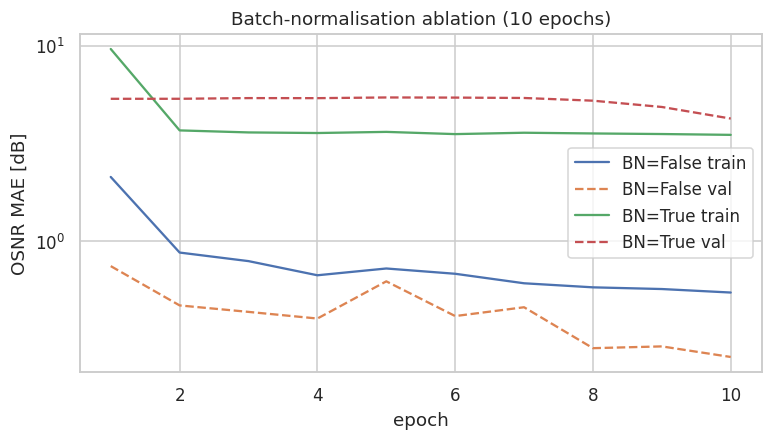

Best validation MAE without BN: 0.256 dB | with BN: 4.235 dB (122 s)


In [28]:
RUN_BN_ABLATION = os.environ.get("OSNR_BN_ABLATION", "0" if QUICK_RUN else "1") == "1"

def short_run(use_bn, epochs=10):
    set_all_seeds()
    m = build_cnn(use_bn=use_bn)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss={"osnr": "mse", "impairment": "sparse_categorical_crossentropy"},
              loss_weights={"osnr": 1.0, "impairment": 0.0}, metrics={"osnr": ["mae"]})
    h = m.fit(ds_train, validation_data=ds_val, epochs=epochs, shuffle=False, verbose=0)
    k_tr = [k for k in h.history if k.startswith("osnr") and "mae" in k][0]
    return pd.Series(h.history[k_tr]), pd.Series(h.history["val_" + k_tr])

if RUN_BN_ABLATION:
    t0 = time.time()
    abl = {}
    for flag in (False, True):
        tr, va = short_run(flag)
        abl[f"BN={flag} train"] = tr; abl[f"BN={flag} val"] = va
    abl = pd.DataFrame(abl); abl.index = np.arange(1, len(abl) + 1)
    ax = abl.plot(figsize=(8, 4), style=["-", "--", "-", "--"], logy=True)
    ax.set_xlabel("epoch"); ax.set_ylabel("OSNR MAE [dB]"); ax.set_title("Batch-normalisation ablation (10 epochs)")
    savefig("bn_ablation"); plt.show()
    print(f"Best validation MAE without BN: {abl['BN=False val'].min():.3f} dB | with BN: {abl['BN=True val'].min():.3f} dB "
          f"({time.time() - t0:.0f} s)")
    abl.to_csv(OUTPUT_DIR / "bn_ablation.csv")
else:
    print("BN ablation skipped.")

## 17. Model Training

* **Optimiser:** Adam, initial learning rate 10⁻³.
* **Loss:** $\mathcal{L} = \frac{1}{\sigma^2}\mathrm{MSE}_\text{OSNR} + \lambda\,\mathrm{CE}_\text{impairment}$ with
  $\lambda = 0.5$.
* **Callbacks:** `EarlyStopping` (patience 12 on validation loss, best weights restored), `ModelCheckpoint` (best model saved as
  `.keras`), `ReduceLROnPlateau` (×0.5 after 5 stagnant epochs), `CSVLogger`.
* Only the **validation** set drives these decisions; the test, unseen‑combination and off‑grid sets are untouched until Section 19.

In [29]:
EPOCHS = 3 if QUICK_RUN else 80
LOSS_WEIGHT_CLS = 0.5
BEST_MODEL_PATH = MODEL_DIR / "osnr_cnn_best.keras"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss={"osnr": "mse", "impairment": "sparse_categorical_crossentropy"},
    loss_weights={"osnr": 1.0 / OSNR_STD ** 2, "impairment": LOSS_WEIGHT_CLS},
    metrics={"osnr": ["mae"], "impairment": ["accuracy"]},
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(str(BEST_MODEL_PATH), monitor="val_loss", save_best_only=True, verbose=0),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    keras.callbacks.CSVLogger(str(OUTPUT_DIR / "training_log.csv")),
]

t0 = time.time()
# shuffling is done inside the tf.data pipeline, so Keras' own shuffle flag is disabled
history = model.fit(ds_train, validation_data=ds_val, epochs=EPOCHS, callbacks=callbacks, shuffle=False, verbose=2)
train_time_s = time.time() - t0
print(f"Training finished in {train_time_s / 60:.1f} min, {len(history.history['loss'])} epochs.")

# Reload the checkpoint so that everything below uses the best validation model from disk
if BEST_MODEL_PATH.exists():
    model = keras.models.load_model(BEST_MODEL_PATH)
    print("Loaded best model from", BEST_MODEL_PATH)

Epoch 1/80
52/52 - 15s - 291ms/step - impairment_accuracy: 0.6559 - impairment_loss: 1.0670 - loss: 0.9983 - osnr_loss: 17.4429 - osnr_mae: 3.2360 - val_impairment_accuracy: 0.7697 - val_impairment_loss: 0.6609 - val_loss: 0.3966 - val_osnr_loss: 1.8817 - val_osnr_mae: 1.1047 - learning_rate: 0.0010
Epoch 2/80
52/52 - 3s - 52ms/step - impairment_accuracy: 0.7777 - impairment_loss: 0.6055 - loss: 0.3586 - osnr_loss: 2.0966 - osnr_mae: 1.1305 - val_impairment_accuracy: 0.7809 - val_impairment_loss: 0.4654 - val_loss: 0.2621 - val_osnr_loss: 0.6387 - val_osnr_mae: 0.6198 - learning_rate: 0.0010
Epoch 3/80
52/52 - 3s - 50ms/step - impairment_accuracy: 0.8373 - impairment_loss: 0.3952 - loss: 0.2477 - osnr_loss: 1.8830 - osnr_mae: 1.0625 - val_impairment_accuracy: 0.8820 - val_impairment_loss: 0.2669 - val_loss: 0.1635 - val_osnr_loss: 0.8208 - val_osnr_mae: 0.7209 - learning_rate: 0.0010
Epoch 4/80
52/52 - 3s - 50ms/step - impairment_accuracy: 0.8836 - impairment_loss: 0.2589 - loss: 0.177

## 18. Training Performance Visualisation

The curves show the total loss, the OSNR MAE (in dB) and the impairment accuracy for training and validation data, plus the
learning‑rate schedule. A validation curve that follows the training curve indicates that the model generalises to new
realisations; a widening gap would indicate over‑fitting.

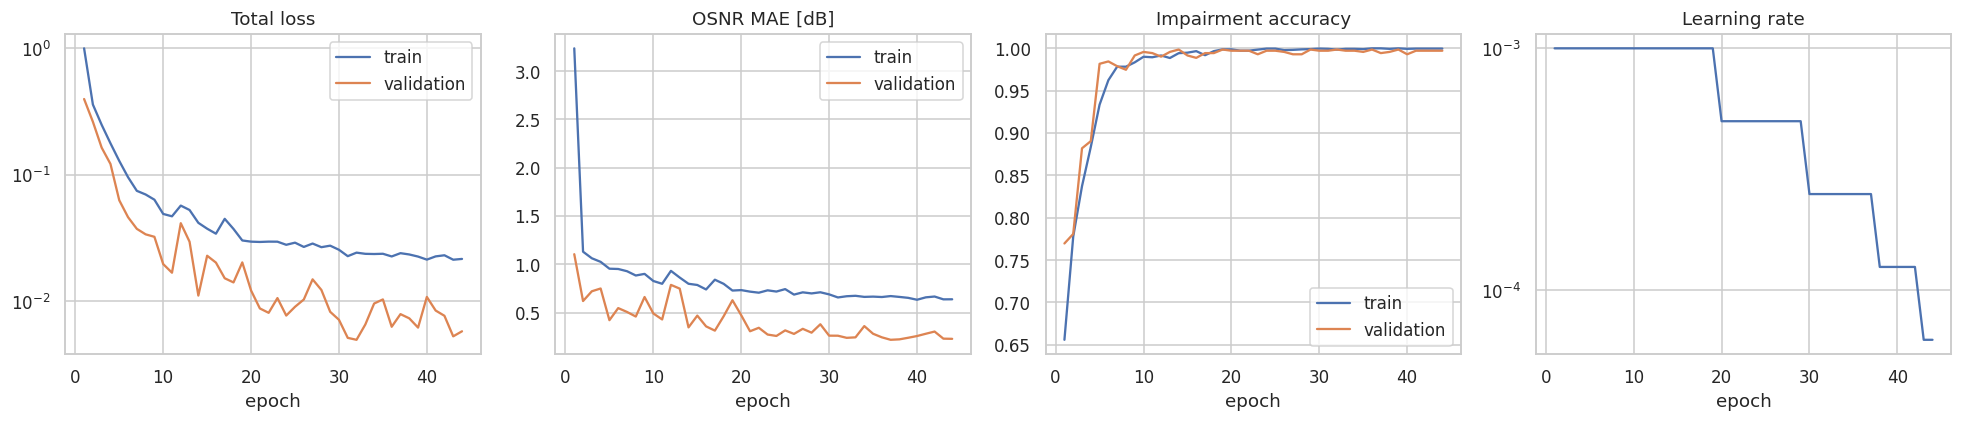

In [30]:
hist = pd.DataFrame(history.history)
hist.index = np.arange(1, len(hist) + 1); hist.index.name = "epoch"
hist.to_csv(OUTPUT_DIR / "training_history.csv")

def find_key(prefix_val, *words):
    # Locate a history column robustly across Keras versions (e.g. 'osnr_mae' vs 'osnr_mean_absolute_error').
    for k in hist.columns:
        if k.startswith("val_") == prefix_val and all(w in k for w in words):
            return k
    return None

panels = [("Total loss", ("loss",), True), ("OSNR MAE [dB]", ("osnr", "mae"), False),
          ("Impairment accuracy", ("impairment", "acc"), False)]
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, words, is_total) in zip(axs, panels):
    k_tr = "loss" if is_total else find_key(False, *words)
    k_va = "val_loss" if is_total else find_key(True, *words)
    if k_tr: ax.plot(hist.index, hist[k_tr], label="train")
    if k_va: ax.plot(hist.index, hist[k_va], label="validation")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
axs[0].set_yscale("log")
lr_key = "learning_rate" if "learning_rate" in hist else ("lr" if "lr" in hist else None)
if lr_key:
    axs[3].semilogy(hist.index, hist[lr_key]); axs[3].set_title("Learning rate"); axs[3].set_xlabel("epoch")
plt.tight_layout(); savefig("training_curves"); plt.show()

## 19. Model Evaluation (OSNR regression)

**Metrics**

* **MAE** $=\frac1N\sum|y-\hat y|$ — average error in dB, directly interpretable.
* **MSE** $=\frac1N\sum(y-\hat y)^2$ — penalises large errors quadratically.
* **RMSE** $=\sqrt{\mathrm{MSE}}$ — same unit as OSNR (dB), sensitive to outliers.
* **R²** $= 1 - \frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$ — fraction of OSNR variance explained (1 = perfect, 0 = predicting the mean).
* We also report the fraction of predictions within ±0.5 dB and ±1 dB, a practical OPM accuracy criterion.

Evaluated sets: **test** (seen combinations, new realisations), **unseen‑combo** (combinations never seen in training) and
**off‑grid** (continuous OSNR and unseen CD values).

In [31]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix, classification_report)

def as_dict(pred):
    # Keras 3 returns a dict for dict-output models; older versions may return a list.
    return pred if isinstance(pred, dict) else {"osnr": pred[0], "impairment": pred[1]}

def predict_all(ds):
    p = as_dict(model.predict(ds, verbose=0))
    return np.asarray(p["osnr"]).ravel(), np.asarray(p["impairment"])

def regression_metrics(y, yhat):
    err = yhat - y
    mse = mean_squared_error(y, yhat)
    return {"N": len(y), "MAE_dB": mean_absolute_error(y, yhat), "MSE_dB2": mse, "RMSE_dB": math.sqrt(mse),
            "R2": r2_score(y, yhat), "bias_dB": float(err.mean()),
            "within_0.5dB_%": 100 * float(np.mean(np.abs(err) <= 0.5)), "within_1dB_%": 100 * float(np.mean(np.abs(err) <= 1.0))}

eval_sets = {
    "test (seen combos)": (ds_test, idx_test, meta_main),
    "unseen combos": (ds_unseen, idx_unseen, meta_main),
    "off-grid": (ds_off, np.arange(len(meta_off)), meta_off),
}
preds, cnn_reg_rows = {}, []
for name, (ds, idx, meta) in eval_sets.items():
    p_osnr, p_cls = predict_all(ds)
    df = meta.iloc[idx][["image_filename", "OSNR_dB", "chromatic_dispersion_ps_nm", "impairment_type"]].copy()
    df["pred_OSNR_dB"] = p_osnr
    df["abs_error_dB"] = np.abs(df.pred_OSNR_dB - df.OSNR_dB)
    df["pred_class"] = [IMPAIRMENT_CLASSES[k] for k in p_cls.argmax(1)]
    preds[name] = df
    cnn_reg_rows.append({"set": name, **regression_metrics(df.OSNR_dB.values, p_osnr)})
cnn_reg = pd.DataFrame(cnn_reg_rows).set_index("set")
display(cnn_reg.round(3))

,N,MAE_dB,MSE_dB2,RMSE_dB,R2,bias_dB,within_0.5dB_%,within_1dB_%
set,,,,,,,,
test (seen combos),713,0.232,0.087,0.296,0.998,-0.095,90.323,99.86
unseen combos,500,0.218,0.077,0.277,0.997,-0.061,91.400,100.00
off-grid,600,0.206,0.070,0.264,0.998,-0.072,93.833,100.00


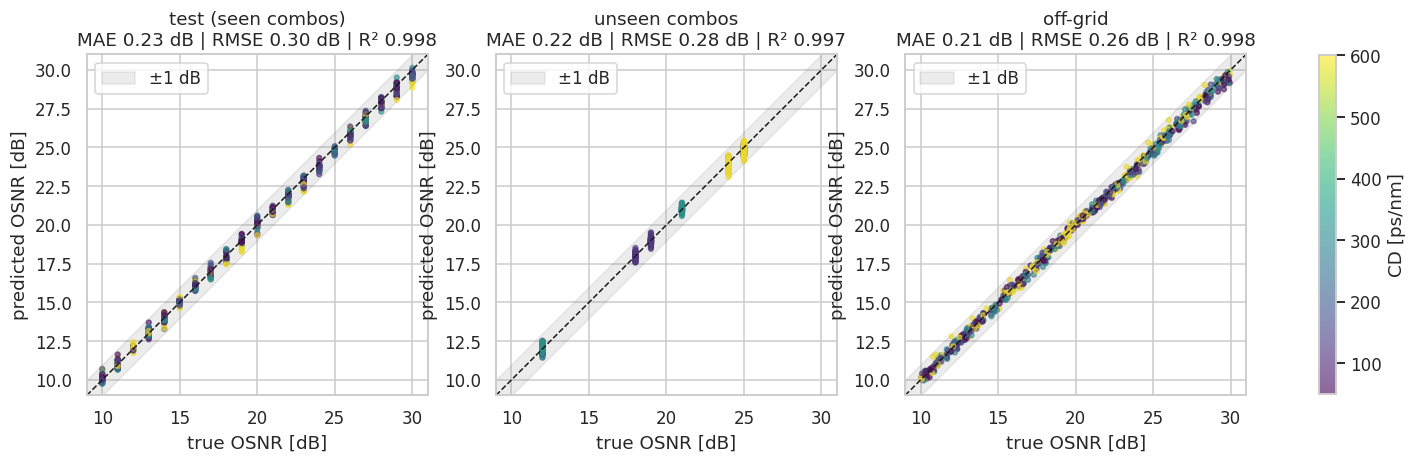

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, df) in zip(axs, preds.items()):
    sc = ax.scatter(df.OSNR_dB, df.pred_OSNR_dB, c=df.chromatic_dispersion_ps_nm, cmap="viridis", s=10, alpha=0.6)
    ax.plot([9, 31], [9, 31], "k--", lw=1); ax.fill_between([9, 31], [8, 30], [10, 32], color="gray", alpha=0.15, label="±1 dB")
    ax.set_xlim(9, 31); ax.set_ylim(9, 31); ax.set_aspect("equal")
    m = cnn_reg.loc[name]
    ax.set_title(f"{name}\nMAE {m.MAE_dB:.2f} dB | RMSE {m.RMSE_dB:.2f} dB | R² {m.R2:.3f}")
    ax.set_xlabel("true OSNR [dB]"); ax.set_ylabel("predicted OSNR [dB]"); ax.legend(loc="upper left")
plt.colorbar(sc, ax=axs, label="CD [ps/nm]", shrink=0.8)
savefig("cnn_actual_vs_predicted"); plt.show()

Points on the dashed diagonal are perfect predictions; the grey band is ±1 dB. The colour shows the dispersion of each sample, so a
dispersion‑dependent bias would appear as a colour‑separated cloud.

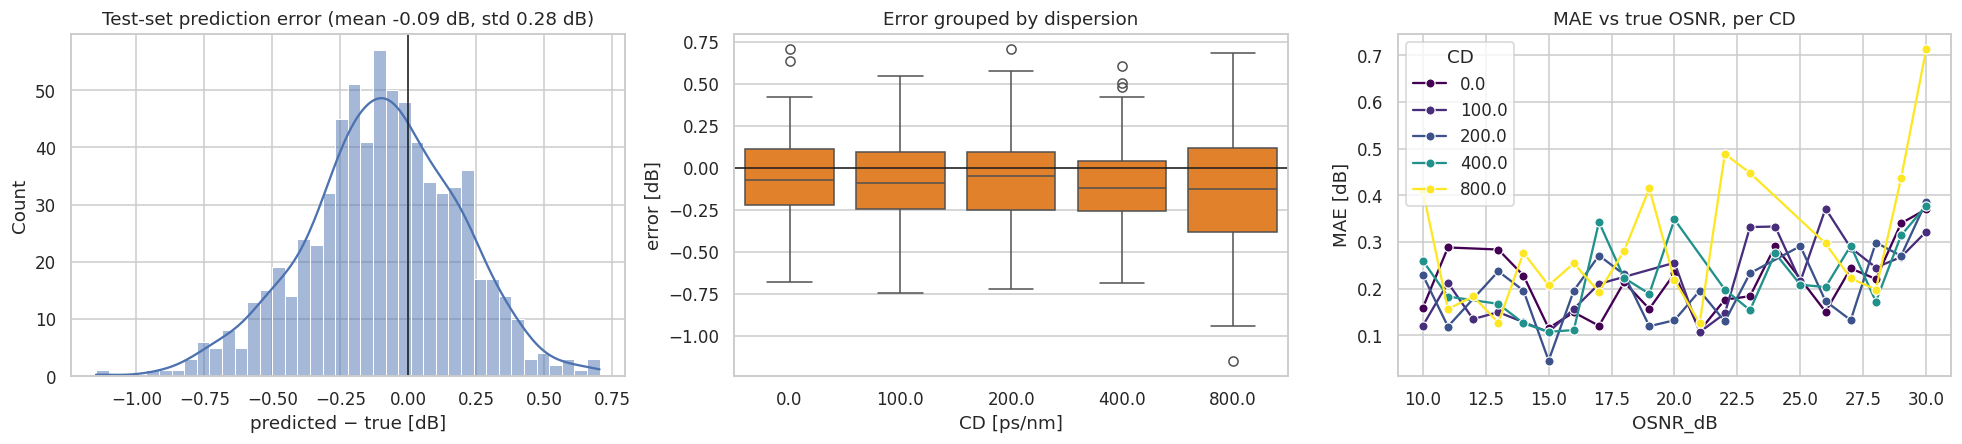

N  MAE_dB  RMSE_dB
set      chromatic_dispersion_ps_nm                        
off-grid 50.0                        154.0   0.194    0.254
         150.0                       147.0   0.185    0.240
         300.0                       139.0   0.234    0.278
         600.0                       160.0   0.214    0.282
test     0.0                         144.0   0.212    0.267
         100.0                       142.0   0.217    0.273
         200.0                       144.0   0.206    0.261
         400.0                       143.0   0.225    0.277
         800.0                       140.0   0.303    0.385

In [33]:
df_t = preds["test (seen combos)"]
err = df_t.pred_OSNR_dB - df_t.OSNR_dB
fig, axs = plt.subplots(1, 3, figsize=(18, 4.2))
sns.histplot(err, bins=40, kde=True, ax=axs[0]); axs[0].axvline(0, color="k", lw=1)
axs[0].set_title(f"Test-set prediction error (mean {err.mean():+.2f} dB, std {err.std():.2f} dB)"); axs[0].set_xlabel("predicted − true [dB]")
sns.boxplot(x=df_t.chromatic_dispersion_ps_nm, y=err, ax=axs[1], color="tab:orange")
axs[1].axhline(0, color="k", lw=1); axs[1].set_title("Error grouped by dispersion"); axs[1].set_xlabel("CD [ps/nm]"); axs[1].set_ylabel("error [dB]")
mae_by = df_t.groupby(["OSNR_dB", "chromatic_dispersion_ps_nm"]).abs_error_dB.mean().reset_index()
sns.lineplot(data=mae_by, x="OSNR_dB", y="abs_error_dB", hue="chromatic_dispersion_ps_nm", palette="viridis", marker="o", ax=axs[2])
axs[2].set_title("MAE vs true OSNR, per CD"); axs[2].set_ylabel("MAE [dB]"); axs[2].legend(title="CD")
plt.tight_layout(); savefig("cnn_error_analysis"); plt.show()

by_cd = (pd.concat([preds["test (seen combos)"], preds["off-grid"]], keys=["test", "off-grid"]).reset_index(level=0)
         .rename(columns={"level_0": "set"})
         .groupby(["set", "chromatic_dispersion_ps_nm"])
         .apply(lambda g: pd.Series({"N": len(g), "MAE_dB": g.abs_error_dB.mean(),
                                     "RMSE_dB": np.sqrt(((g.pred_OSNR_dB - g.OSNR_dB) ** 2).mean())}), include_groups=False))
display(by_cd.round(3))

**Reading the error analysis.** The histogram shows bias (mean) and spread (std) of the error. The box plot and the per‑CD table
answer whether dispersion degrades OSNR estimation (ISI and noise both close the eye, so a CD‑dependent error increase is
physically plausible). The MAE‑vs‑OSNR curve typically rises at high OSNR: above ≈ 25 dB the rails are already very thin, the
eye changes little per dB, and the residual ISI/finite‑pattern effects dominate — OSNR becomes intrinsically harder to resolve.
The table below lists individual predictions.

In [34]:
# Table of actual vs predicted OSNR (20 random test samples + the unseen-combination summary)
table = df_t.sample(20, random_state=GLOBAL_SEED)[["image_filename", "chromatic_dispersion_ps_nm", "OSNR_dB", "pred_OSNR_dB", "abs_error_dB"]]
display(table.round(2).reset_index(drop=True))

unseen_summary = (preds["unseen combos"].groupby(["chromatic_dispersion_ps_nm", "OSNR_dB"])
                  .agg(N=("pred_OSNR_dB", "size"), mean_pred_dB=("pred_OSNR_dB", "mean"), std_pred_dB=("pred_OSNR_dB", "std"),
                       MAE_dB=("abs_error_dB", "mean")).round(2))
print("Predictions on OSNR/CD combinations that were never seen during training:")
display(unseen_summary)

,image_filename,chromatic_dispersion_ps_nm,OSNR_dB,pred_OSNR_dB,abs_error_dB
0,eye_04626.png,800.0,18.0,18.129999,0.13
1,eye_04846.png,800.0,22.0,21.520000,0.48
2,eye_04155.png,400.0,30.0,30.129999,0.13
3,eye_01432.png,100.0,17.0,17.410000,0.41
4,eye_02437.png,200.0,16.0,15.730000,0.27
5,eye_03936.png,400.0,25.0,24.730000,0.27
6,eye_02957.png,200.0,27.0,27.360001,0.36
7,eye_00050.png,0.0,10.0,10.030000,0.03
8,eye_02196.png,200.0,11.0,11.100000,0.10
9,eye_04024.png,400.0,27.0,26.830000,0.17


Predictions on OSNR/CD combinations that were never seen during training:


N  mean_pred_dB  std_pred_dB  MAE_dB
chromatic_dispersion_ps_nm OSNR_dB                                       
0.0                        12.0     50     12.020000         0.21    0.17
                           25.0     50     24.809999         0.23    0.24
100.0                      18.0     50     18.000000         0.21    0.16
                           19.0     50     18.969999         0.21    0.16
200.0                      12.0     50     12.070000         0.23    0.19
                           24.0     50     23.799999         0.25    0.27
400.0                      12.0     50     12.120000         0.22    0.21
                           21.0     50     21.020000         0.18    0.13
800.0                      24.0     50     23.790001         0.32    0.32
                           25.0     50     24.790001         0.33    0.32

## 20. Impairment Classification

**Metrics**

* **Accuracy** — fraction of correctly classified eyes (can be misleading with imbalanced classes).
* **Precision** (per class) — of all eyes predicted as class *c*, how many truly are *c* (false alarms).
* **Recall** (per class) — of all eyes truly in class *c*, how many were found (missed detections).
* **F1** — harmonic mean of precision and recall. **Macro** averages weight every class equally, which is appropriate for our
  imbalanced classes.
* **Confusion matrix** — rows = true class, columns = predicted class; off‑diagonal cells reveal *which* impairments are confused.

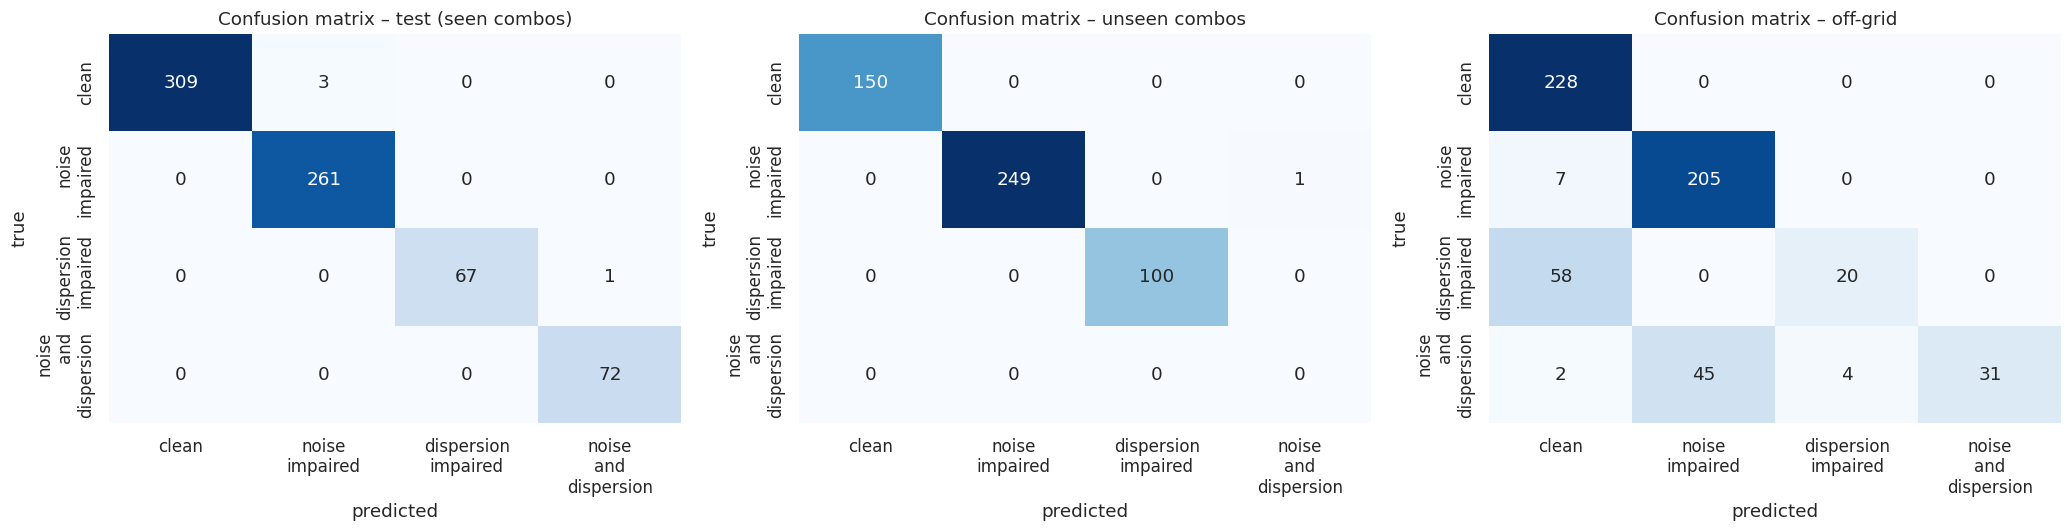

,accuracy,macro_precision,macro_recall,macro_F1
set,,,,
test (seen combos),0.994,0.994,0.994,0.994
unseen combos,0.998,0.750,0.749,0.749
off-grid,0.807,0.857,0.650,0.675


Detailed report – test set (seen combinations):
                      precision    recall  f1-score   support

               clean      1.000     0.990     0.995       312
      noise_impaired      0.989     1.000     0.994       261
 dispersion_impaired      1.000     0.985     0.993        68
noise_and_dispersion      0.986     1.000     0.993        72

            accuracy                          0.994       713
           macro avg      0.994     0.994     0.994       713
        weighted avg      0.994     0.994     0.994       713



In [35]:
cls_rows = []
fig, axs = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, df) in zip(axs, preds.items()):
    y_true = df.impairment_type.map(CLASS_TO_INDEX).values
    y_pred = df.pred_class.map(CLASS_TO_INDEX).values
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0,
                                                  labels=range(len(IMPAIRMENT_CLASSES)))
    cls_rows.append({"set": name, "accuracy": accuracy_score(y_true, y_pred), "macro_precision": p, "macro_recall": r, "macro_F1": f1})
    cm = confusion_matrix(y_true, y_pred, labels=range(len(IMPAIRMENT_CLASSES)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=[c.replace("_", "\n") for c in IMPAIRMENT_CLASSES], yticklabels=[c.replace("_", "\n") for c in IMPAIRMENT_CLASSES])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix – {name}")
plt.tight_layout(); savefig("cnn_confusion_matrices"); plt.show()
cnn_cls = pd.DataFrame(cls_rows).set_index("set")
display(cnn_cls.round(3))

print("Detailed report – test set (seen combinations):")
dt = preds["test (seen combos)"]
print(classification_report(dt.impairment_type, dt.pred_class, labels=IMPAIRMENT_CLASSES, digits=3, zero_division=0))

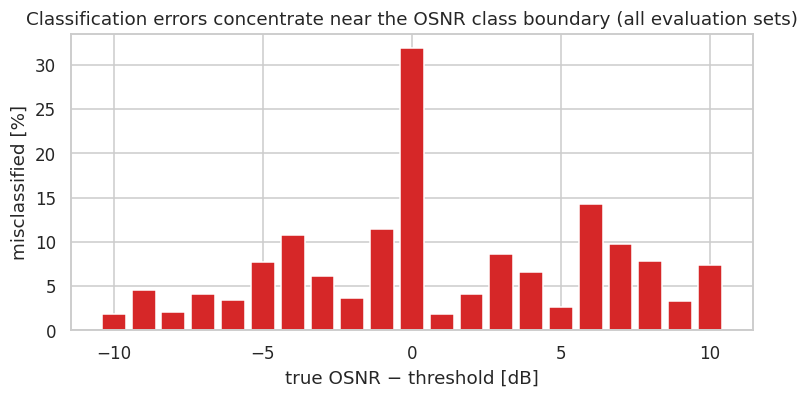

In [36]:
# Where do classification errors occur? Error rate as a function of distance to the OSNR threshold.
d_all = pd.concat(preds.values(), keys=preds.keys()).reset_index(level=0).rename(columns={"level_0": "set"})
d_all["wrong"] = d_all.impairment_type != d_all.pred_class
d_all["dist_to_osnr_thr_dB"] = (d_all.OSNR_dB - OSNR_THRESHOLD_DB).round(0)
err_vs_dist = d_all.groupby("dist_to_osnr_thr_dB").wrong.mean()
plt.figure(figsize=(8, 3.5)); plt.bar(err_vs_dist.index, 100 * err_vs_dist.values, color="tab:red")
plt.xlabel("true OSNR − threshold [dB]"); plt.ylabel("misclassified [%]")
plt.title("Classification errors concentrate near the OSNR class boundary (all evaluation sets)")
savefig("cls_errors_vs_threshold_distance"); plt.show()

Because the class boundaries are hard thresholds on continuous physical quantities, misclassifications are expected mainly for
eyes whose OSNR lies within ≈ 1 dB of 20 dB, and — in the off‑grid set — for CD values never seen in training that lie close to
the 500 ps/nm boundary (300 and especially 600 ps/nm). Errors far from
the thresholds would indicate a real modelling problem; errors at the boundary mostly reflect the arbitrariness of a sharp
threshold. In practice the regression output (with its uncertainty) is the more informative quantity, and the class label is a
convenient alarm.

## 21. Baseline Model Comparison

To judge whether the CNN brings a real benefit, we train simpler models on the **same splits**:

1. **Hand‑crafted eye features + Random Forest** (in the spirit of Jargon *et al.* 2009). Features are measured *on the image*
   (the CNN's input), using the intensity at the sampling instant and at the crossings: mean levels and standard deviations of the
   "1" and "0" rails, an image‑based Q‑factor, eye opening, eye height ratio, crossing level and spread, eye width at the decision
   level, occupancy, and a 16‑bin amplitude profile at the eye centre (≈ 35 features).
2. **Same features + Support Vector Regression (RBF kernel)** — a strong non‑linear regressor on standardised features.
3. **Fully connected neural network on raw pixels** (images down‑sampled to 32×32 = 1024 inputs; two hidden layers of 256 and 64
   ReLU units, Adam, early stopping) — tests whether convolutional structure matters.

For classification we also train a Random‑Forest classifier on the hand‑crafted features.

In [37]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Y_AXIS = np.linspace(SIM_CFG.y_max, SIM_CFG.y_min, IMG_SIZE)   # amplitude of each image row (row 0 = top)

def eye_image_features(img_u8: np.ndarray) -> np.ndarray:
    # Hand-crafted eye-diagram parameters measured from a 128x128 eye image (uint8).
    img = img_u8[..., 0].astype(np.float64) / 255.0
    w = np.expm1(img * 6.0)                       # approximate inversion of the log intensity mapping
    c = IMG_SIZE // 2                             # sampling instant (eye centre) column
    prof = w[:, c - 3:c + 4].sum(1) + 1e-12       # vertical histogram at the sampling instant
    thr = np.sum(prof * Y_AXIS) / prof.sum()      # decision threshold ~ mean level
    up, lo = Y_AXIS > thr, Y_AXIS <= thr
    def wstats(mask):
        pw = prof[mask]; yv = Y_AXIS[mask]
        mu = np.sum(pw * yv) / pw.sum(); sd = np.sqrt(np.sum(pw * (yv - mu) ** 2) / pw.sum())
        return mu, sd
    mu1, s1 = wstats(up); mu0, s0 = wstats(lo)
    q_img = (mu1 - mu0) / (s1 + s0 + 1e-9)
    eye_open = (mu1 - 3 * s1) - (mu0 + 3 * s0)
    # crossing region (columns at 0.5 UI and 1.5 UI)
    feats_x = []
    for cx in (IMG_SIZE // 4, 3 * IMG_SIZE // 4):
        pc = w[:, cx - 2:cx + 3].sum(1) + 1e-12
        m = np.sum(pc * Y_AXIS) / pc.sum(); sdev = np.sqrt(np.sum(pc * (Y_AXIS - m) ** 2) / pc.sum())
        feats_x += [m, sdev]
    # eye width: fraction of columns that are empty at the decision-threshold row (+/- 2 rows)
    r_thr = int(np.argmin(np.abs(Y_AXIS - thr)))
    band = img[max(r_thr - 2, 0):r_thr + 3, :]
    eye_width = float(np.mean(band.max(0) < 0.05))
    occupancy = float(np.mean(img > 0)); mean_int = float(img.mean())
    top_occ = float(np.mean(img[: IMG_SIZE // 8] > 0))     # overshoot region (CD signature)
    prof16 = prof.reshape(16, -1).sum(1); prof16 = prof16 / prof16.sum()
    return np.array([mu1, s1, mu0, s0, q_img, eye_open, (mu1 - mu0), s1 / (s0 + 1e-9), thr,
                     *feats_x, eye_width, occupancy, mean_int, top_occ, *prof16], dtype=np.float64)

FEATURE_NAMES = (["mu1", "sigma1", "mu0", "sigma0", "Q_img", "eye_opening", "eye_amplitude", "sigma_ratio", "threshold",
                  "cross1_level", "cross1_spread", "cross2_level", "cross2_spread", "eye_width", "occupancy",
                  "mean_intensity", "overshoot_occupancy"] + [f"profile_{k}" for k in range(16)])

t0 = time.time()
F_all = np.stack([eye_image_features(x) for x in X_all])
F_off = np.stack([eye_image_features(x) for x in X_off])
print(f"Feature matrix {F_all.shape} computed in {time.time() - t0:.1f} s")

def downsample32(X):
    # 128x128 -> 32x32 by 4x4 average pooling, flattened, scaled to [0,1]
    return X[..., 0].reshape(len(X), 32, 4, 32, 4).mean((2, 4)).reshape(len(X), -1) / 255.0
P_all, P_off = downsample32(X_all), downsample32(X_off)

Feature matrix (5250, 33) computed in 2.6 s


In [38]:
set_all_seeds()
eval_index = {"test (seen combos)": idx_test, "unseen combos": idx_unseen}
y_tr = y_osnr_all[idx_train]

baselines = {
    "Random Forest (eye features)": (make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                                                         random_state=GLOBAL_SEED)), "feat"),
    "SVR-RBF (eye features)": (make_pipeline(StandardScaler(), SVR(C=10.0, epsilon=0.1, gamma="scale")), "feat"),
    "MLP (32×32 pixels)": (make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(256, 64), early_stopping=True,
                                                                        max_iter=300, random_state=GLOBAL_SEED)), "pix"),
}
base_rows, base_preds = [], {}
for bname, (est, kind) in baselines.items():
    Xtr = F_all[idx_train] if kind == "feat" else P_all[idx_train]
    t0 = time.time(); est.fit(Xtr, y_tr); fit_s = time.time() - t0
    for sname in ["test (seen combos)", "unseen combos", "off-grid"]:
        if sname == "off-grid":
            Xe, ye = (F_off if kind == "feat" else P_off), y_osnr_off
        else:
            Xe = (F_all if kind == "feat" else P_all)[eval_index[sname]]; ye = y_osnr_all[eval_index[sname]]
        yhat = est.predict(Xe)
        base_preds[(bname, sname)] = yhat
        base_rows.append({"model": bname, "set": sname, **regression_metrics(ye, yhat)})
    print(f"{bname}: fitted in {fit_s:.1f} s")

cnn_rows = [{"model": "CNN (multi-task)", "set": s, **cnn_reg.loc[s].to_dict()} for s in cnn_reg.index]
comparison = pd.DataFrame(cnn_rows + base_rows)
comparison_table = comparison.pivot_table(index="model", columns="set", values=["MAE_dB", "RMSE_dB", "R2"]).round(3)
display(comparison_table)
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

# Random-Forest classifier baseline for the impairment task
rfc = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=GLOBAL_SEED).fit(F_all[idx_train], y_cls_all[idx_train])
rfc_rows = []
for sname, (Xe, ye) in {"test (seen combos)": (F_all[idx_test], y_cls_all[idx_test]),
                        "unseen combos": (F_all[idx_unseen], y_cls_all[idx_unseen]),
                        "off-grid": (F_off, y_cls_off)}.items():
    yp = rfc.predict(Xe)
    p, r, f1, _ = precision_recall_fscore_support(ye, yp, average="macro", zero_division=0, labels=range(4))
    rfc_rows.append({"set": sname, "accuracy": accuracy_score(ye, yp), "macro_precision": p, "macro_recall": r, "macro_F1": f1})
cls_comparison = pd.concat([cnn_cls.assign(model="CNN (multi-task)").reset_index(),
                            pd.DataFrame(rfc_rows).assign(model="Random Forest (eye features)")]).set_index(["model", "set"]).round(3)
display(cls_comparison)

Random Forest (eye features): fitted in 16.3 s
SVR-RBF (eye features): fitted in 0.9 s
MLP (32×32 pixels): fitted in 14.7 s


MAE_dB                                   \
set                          off-grid test (seen combos) unseen combos   
model                                                                    
CNN (multi-task)                0.206              0.232         0.218   
MLP (32×32 pixels)              0.420              0.323         0.335   
Random Forest (eye features)    0.388              0.108         0.298   
SVR-RBF (eye features)          0.202              0.171         0.158   

                                   R2                                   \
set                          off-grid test (seen combos) unseen combos   
model                                                                    
CNN (multi-task)                0.998              0.998         0.997   
MLP (32×32 pixels)              0.989              0.995         0.993   
Random Forest (eye features)    0.990              0.999         0.993   
SVR-RBF (eye features)          0.997              0.997         0.998   

                              RMSE_dB                                   
set                          off-grid test (seen combos) unseen combos  
model                                                                   
CNN (multi-task)                0.264              0.296         0.277  
MLP (32×32 pixels)              0.593              0.443         0.451  
Random Forest (eye features)    0.566              0.209         0.453  
SVR-RBF (eye features)          0.304              0.311         0.212

accuracy  macro_precision  \
model                        set                                             
CNN (multi-task)             test (seen combos)     0.994            0.994   
                             unseen combos          0.998            0.750   
                             off-grid               0.807            0.857   
Random Forest (eye features) test (seen combos)     0.997            0.996   
                             unseen combos          1.000            0.750   
                             off-grid               0.825            0.803   

                                                 macro_recall  macro_F1  
model                        set                                         
CNN (multi-task)             test (seen combos)         0.994     0.994  
                             unseen combos              0.749     0.749  
                             off-grid                   0.650     0.675  
Random Forest (eye features) test (seen combos)         0.998     0.997  
                             unseen combos              0.750     0.750  
                             off-grid                   0.683     0.703

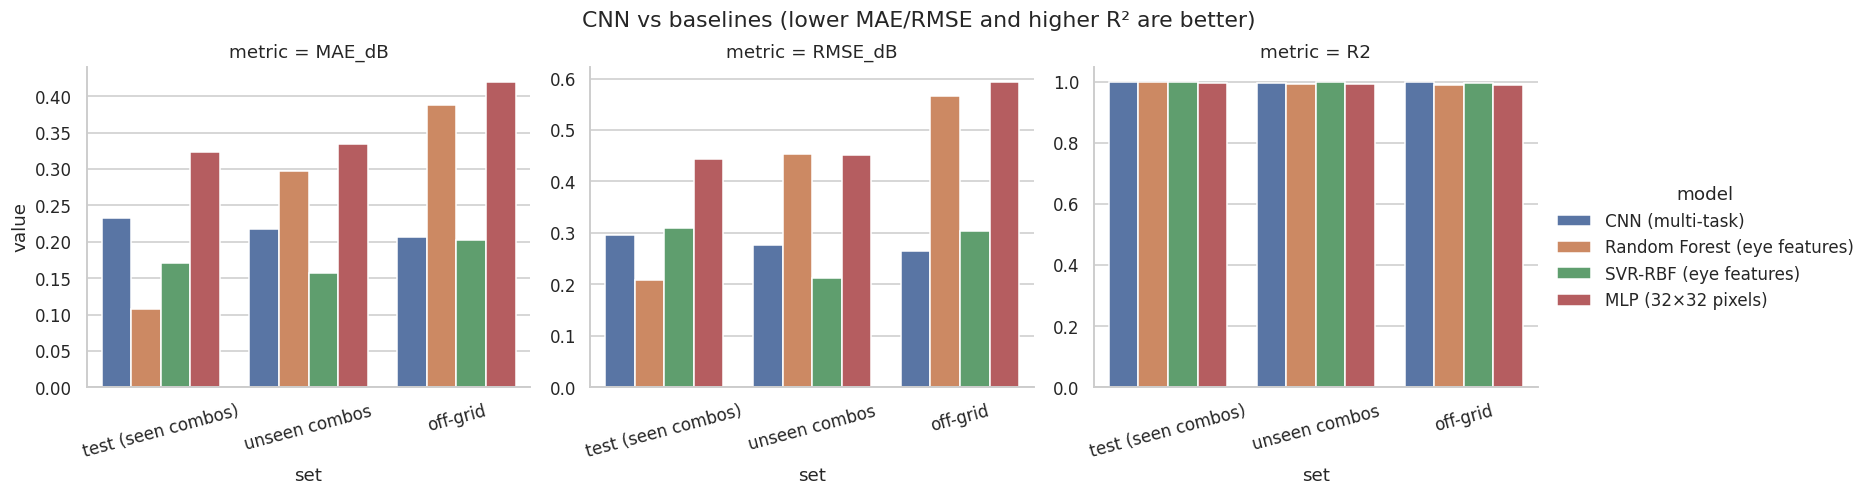

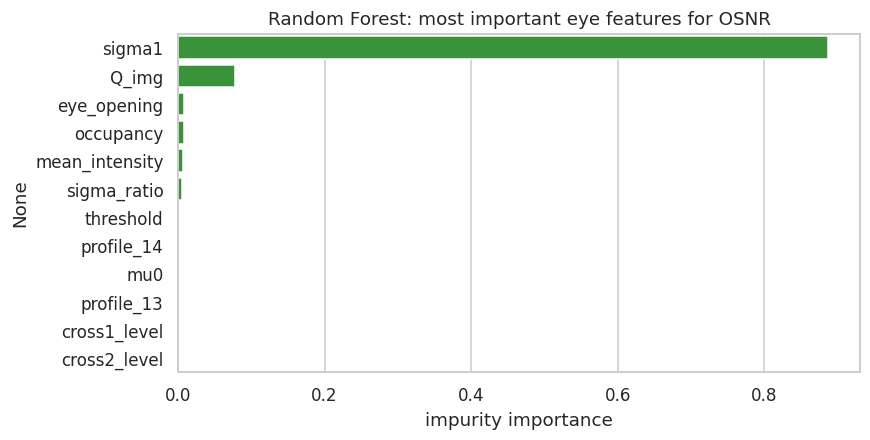

In [39]:
plot_df = comparison[["model", "set", "MAE_dB", "RMSE_dB", "R2"]].melt(id_vars=["model", "set"], var_name="metric")
g = sns.catplot(data=plot_df, x="set", y="value", hue="model", col="metric", kind="bar", sharey=False, height=4, aspect=1.2)
g.set_xticklabels(rotation=15); g.fig.suptitle("CNN vs baselines (lower MAE/RMSE and higher R² are better)", y=1.03)
plt.savefig(PLOTS_DIR / "model_comparison.png"); plt.show()

# Which hand-crafted features does the Random Forest rely on?
rf = baselines["Random Forest (eye features)"][0][-1]
imp = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)[:12]
plt.figure(figsize=(8, 4)); sns.barplot(x=imp.values, y=imp.index, color="tab:green")
plt.title("Random Forest: most important eye features for OSNR"); plt.xlabel("impurity importance")
savefig("rf_feature_importance"); plt.show()

**How to read the comparison.** If the CNN's MAE/RMSE are clearly lower (and R² higher) than those of the feature‑based models
on *all three* evaluation sets, the CNN extracts information beyond classical eye parameters — for example by jointly accounting
for the CD‑induced trace structure when estimating noise. If a baseline is close, the classical parameters (especially the
rail standard deviations and the image Q‑factor, see the feature importances) already capture most of the OSNR information in this
simulated, single‑format system — an honest and useful finding. The conclusion is printed with the actual numbers in Section 24.

## 22. Prediction on New Eye Diagrams

`predict_eye_image()` applies **exactly** the training preprocessing (`preprocess_image`: grayscale → 128×128 bilinear → /255,
inversion of light‑background images), then returns the predicted OSNR (dB) and the impairment class with its probabilities.

1. First we demonstrate it on an eye diagram freshly simulated with **parameters that never appear in the dataset**
   (OSNR = 16.3 dB, CD = 250 ps/nm, new seed), saved to PNG and read back from disk like any external file.
2. Then you can **upload your own eye‑diagram image** (Colab file‑upload dialog).

> ⚠️ **Domain‑shift warning.** The model only knows *this* simulated system: 10 Gb/s NRZ‑OOK, ER = 12 dB, 50 GHz optical filter,
> 0.75·R_b Bessel receiver, 2‑UI window, amplitude normalised to the mean and displayed over [−0.3, 3.4], log‑intensity grayscale
> rendering on a black background. Eye diagrams from oscilloscopes or other simulators (different bit rate, scale, colour map,
> axes/grid lines, text overlays, persistence settings, modulation format, chirp, PMD, non‑linearities…) violate these assumptions,
> and the predicted OSNR may be **unreliable**. Use `render_eye()` on your own waveforms to match the format.

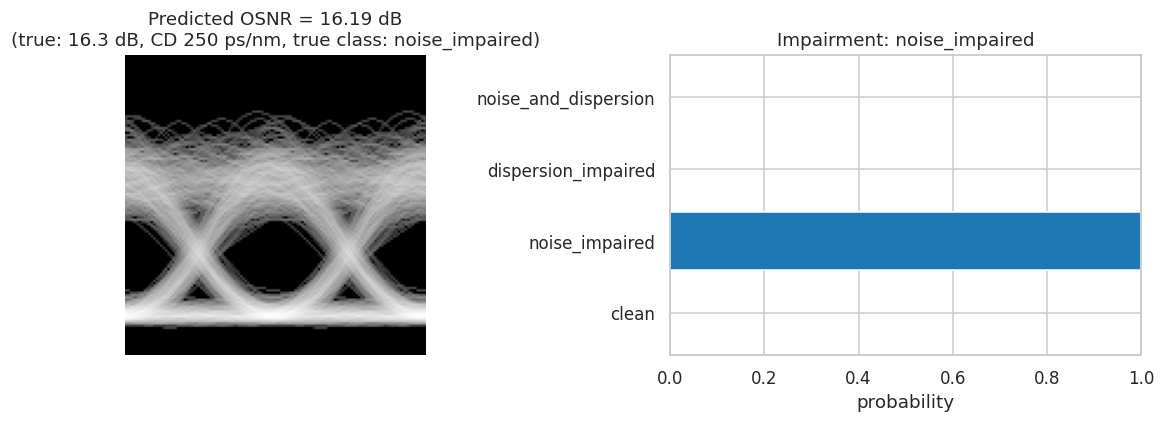

Predicted OSNR: 16.19 dB (0.1 nm ref.) | impairment class: noise_impaired | probabilities: {'clean': 0.0, 'noise_impaired': 1.0, 'dispersion_impaired': 0.0, 'noise_and_dispersion': 0.0}


In [40]:
def predict_eye_image(path, show=True, title_extra=""):
    x = preprocess_image(path, verbose=True)
    p = as_dict(model.predict(x[None], verbose=0))
    osnr_hat = float(np.asarray(p["osnr"]).ravel()[0])
    probs = np.asarray(p["impairment"])[0]
    cls = IMPAIRMENT_CLASSES[int(probs.argmax())]
    if show:
        fig, axs = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.3]})
        axs[0].imshow(x[..., 0], cmap="gray", vmin=0, vmax=1); axs[0].axis("off")
        axs[0].set_title(f"Predicted OSNR = {osnr_hat:.2f} dB{title_extra}")
        axs[1].barh(IMPAIRMENT_CLASSES, probs, color="tab:blue"); axs[1].set_xlim(0, 1)
        axs[1].set_title(f"Impairment: {cls}"); axs[1].set_xlabel("probability")
        plt.tight_layout(); plt.show()
    print(f"Predicted OSNR: {osnr_hat:.2f} dB (0.1 nm ref.) | impairment class: {cls} "
          f"| probabilities: { {c: round(float(p_), 3) for c, p_ in zip(IMPAIRMENT_CLASSES, probs)} }")
    return osnr_hat, cls, probs

# --- Demo with a brand-new simulated eye diagram (parameters not in the dataset) ---
demo_osnr, demo_cd, demo_seed = 16.3, 250.0, 123_456_789
wf_demo, _ = simulate_link(demo_osnr, demo_cd, demo_seed, SIM_CFG)
demo_path = OUTPUT_DIR / "demo_unseen_eye.png"
Image.fromarray(render_eye(wf_demo, SIM_CFG)).save(demo_path)
_ = predict_eye_image(demo_path, title_extra=f"\n(true: {demo_osnr} dB, CD {demo_cd:g} ps/nm, "
                                             f"true class: {impairment_label(demo_osnr, demo_cd, OSNR_THRESHOLD_DB, CD_THRESHOLD_PS_NM)})")

**Upload your own eye diagram.** Run the next cell and choose one or more image files (PNG/JPG). In Colab a file picker appears;
outside Colab the cell explains how to call `predict_eye_image()` with a file path instead.

In [41]:
if IN_COLAB:
    from google.colab import files
    try:
        uploaded = files.upload()          # opens the file-picker; press "Cancel" to skip
    except Exception as exc:
        uploaded = {}
        print("Upload cancelled or failed:", repr(exc))
    for fname, content in uploaded.items():
        up_path = OUTPUT_DIR / f"uploaded_{Path(fname).name}"
        up_path.write_bytes(content)
        try:
            predict_eye_image(up_path, title_extra=f"\n{fname}")
        except Exception as exc:
            print(f"Could not process {fname}: {exc!r}")
    if not uploaded:
        print("No file uploaded.")
else:
    print("Not running in Colab - call predict_eye_image('path/to/eye.png') to analyse a local image.")

No file uploaded.


## 23. Model Export

Saved to `OUTPUT_DIR` (Google Drive → `MyDrive/OSNR_Eye_Project` in Colab):

| File | Content |
|---|---|
| `model/osnr_cnn_best.keras` | Best model (architecture + weights + optimiser state) — reload with `keras.models.load_model` |
| `model/osnr_cnn.weights.h5` | Weights only |
| `training_history.csv`, `training_history.json`, `training_log.csv` | Per‑epoch losses/metrics |
| `label_mapping.json` | Impairment classes ↔ indices and their physical definitions |
| `preprocessing_config.json` | Image preprocessing + simulation configuration (needed to reproduce inputs) |
| `metadata.csv`, `metadata_with_splits.csv` | Dataset labels and split assignment |
| `model_comparison.csv`, `performance_report.md` | Metrics and a written report generated from the actual results |
| `plots/*.png` | All figures |
| `OSNR_Dataset.zip` | Zipped dataset backup |

A zip of all lightweight artefacts (everything except the dataset archives) is created and offered for download.

In [42]:
model.save(MODEL_DIR / "osnr_cnn_best.keras")
model.save_weights(str(MODEL_DIR / "osnr_cnn.weights.h5"))
hist.to_json(OUTPUT_DIR / "training_history.json", orient="columns", indent=1)
shutil.copy(DATA_ROOT / "metadata.csv", OUTPUT_DIR / "metadata.csv")

label_mapping = {
    "classes": {i: c for i, c in enumerate(IMPAIRMENT_CLASSES)},
    "definitions": {
        "clean": f"OSNR >= {OSNR_THRESHOLD_DB} dB and |CD| < {CD_THRESHOLD_PS_NM} ps/nm",
        "noise_impaired": f"OSNR < {OSNR_THRESHOLD_DB} dB and |CD| < {CD_THRESHOLD_PS_NM} ps/nm",
        "dispersion_impaired": f"OSNR >= {OSNR_THRESHOLD_DB} dB and |CD| >= {CD_THRESHOLD_PS_NM} ps/nm",
        "noise_and_dispersion": f"OSNR < {OSNR_THRESHOLD_DB} dB and |CD| >= {CD_THRESHOLD_PS_NM} ps/nm",
    },
    "osnr_unit": "dB, 0.1 nm reference bandwidth (12.48 GHz at 1550 nm)",
}
(OUTPUT_DIR / "label_mapping.json").write_text(json.dumps(label_mapping, indent=2))
(OUTPUT_DIR / "preprocessing_config.json").write_text(json.dumps(
    {"preprocessing": PREPROCESS_CONFIG, "simulation": asdict(SIM_CFG),
     "osnr_reference_bandwidth_Hz": SIM_CFG.osnr_ref_bw_hz, "held_out_combinations": sorted(held_out_combos)}, indent=2))

# ----------------------------- performance report (generated from the actual results) -----------------------------
def df_md(df):
    # Markdown table without the optional 'tabulate' dependency.
    df = df.reset_index()
    cols = [" / ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |")
    return "\n".join(lines)

report = f'''# OSNR estimation from eye diagrams - performance report

*Generated automatically on {time.strftime("%Y-%m-%d %H:%M")} from a notebook run. SIMULATED DATA - not laboratory measurements.*

* Dataset: {len(meta_main)} eye diagrams ({len(OSNR_GRID)} OSNR levels x {len(CD_LEVELS_PS_NM)} CD levels x {N_REALIZATIONS} realisations), off-grid set: {len(meta_off)}
* Split: train {len(idx_train)}, val {len(idx_val)}, test {len(idx_test)}, unseen-combination {len(idx_unseen)}
* Held-out combinations: {", ".join(sorted(held_out_combos))}
* Training: {len(hist)} epochs, {train_time_s / 60:.1f} min, QUICK_RUN = {QUICK_RUN}
* Back-to-back OSNR for Q = 6 in this simulated system: {req_osnr_q6:.1f} dB

## CNN - OSNR regression
{df_md(cnn_reg.round(3))}

## CNN - impairment classification
{df_md(cnn_cls.round(3))}

## Comparison with baselines (OSNR regression)
{df_md(comparison_table)}

## Classification comparison
{df_md(cls_comparison)}
'''
(OUTPUT_DIR / "performance_report.md").write_text(report)

# Zip lightweight artefacts for download
artefact_zip = BASE_LOCAL / "OSNR_project_outputs.zip"
with zipfile.ZipFile(artefact_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file() and p.suffix != ".zip":
            zf.write(p, p.relative_to(OUTPUT_DIR.parent))
print("Saved artefacts:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUTPUT_DIR)}  ({p.stat().st_size / 1e3:.0f} kB)")
print("Download bundle:", artefact_zip)

if IN_COLAB:
    from google.colab import files
    try:
        files.download(str(artefact_zip))                 # model, metadata, plots, report
    except Exception as exc:
        print("Browser download failed (files remain on Google Drive):", repr(exc))

Saved artefacts:
  OSNR_Dataset.zip  (20909 kB)
  OSNR_Dataset_offgrid.zip  (2384 kB)
  bn_ablation.csv  (1 kB)
  demo_unseen_eye.png  (4 kB)
  label_mapping.json  (0 kB)
  metadata.csv  (322 kB)
  metadata_with_splits.csv  (355 kB)
  model/osnr_cnn.weights.h5  (19094 kB)
  model/osnr_cnn_best.keras  (19111 kB)
  model_comparison.csv  (2 kB)
  performance_report.md  (3 kB)
  plots/bn_ablation.png  (64 kB)
  plots/cls_errors_vs_threshold_distance.png  (41 kB)
  plots/cnn_actual_vs_predicted.png  (156 kB)
  plots/cnn_confusion_matrices.png  (86 kB)
  plots/cnn_error_analysis.png  (209 kB)
  plots/eda_counts.png  (101 kB)
  plots/eda_grid_osnr_cd.png  (880 kB)
  plots/eda_mean_eyes.png  (91 kB)
  plots/eda_occupancy.png  (133 kB)
  plots/eda_offgrid_and_grid.png  (82 kB)
  plots/eye_line_vs_histogram.png  (546 kB)
  plots/link_waveforms.png  (158 kB)
  plots/model_comparison.png  (107 kB)
  plots/optical_spectrum.png  (124 kB)
  plots/physics_ber_and_cd_penalty.png  (136 kB)
  plots/rando

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 24. Results and Discussion

The cell below prints the key numbers **computed in this run** and derives the qualitative conclusions from them (no result is
hard‑coded). The discussion that follows explains how to interpret them.

In [43]:
print(report)

best_base = comparison[(comparison.model != "CNN (multi-task)") & (comparison.set == "test (seen combos)")].sort_values("MAE_dB").iloc[0]
cnn_t = cnn_reg.loc["test (seen combos)"]
gain = 100 * (best_base.MAE_dB - cnn_t.MAE_dB) / best_base.MAE_dB
print(f"Best baseline on the test set: {best_base.model} (MAE {best_base.MAE_dB:.3f} dB).")
print(f"CNN test MAE {cnn_t.MAE_dB:.3f} dB -> relative MAE change vs best baseline: {gain:+.1f}% "
      f"({'CNN better' if gain > 0 else 'baseline better or equal'}).")
for s in ["unseen combos", "off-grid"]:
    print(f"Generalisation - {s}: CNN MAE {cnn_reg.loc[s].MAE_dB:.3f} dB vs test {cnn_t.MAE_dB:.3f} dB "
          f"(ratio {cnn_reg.loc[s].MAE_dB / cnn_t.MAE_dB:.2f}).")

# OSNR estimation from eye diagrams - performance report

*Generated automatically on 2026-11-20 14:45 from a notebook run. SIMULATED DATA - not laboratory measurements.*

* Dataset: 5250 eye diagrams (21 OSNR levels x 5 CD levels x 50 realisations), off-grid set: 600
* Split: train 3325, val 712, test 713, unseen-combination 500
* Held-out combinations: osnr12_cd0, osnr12_cd200, osnr12_cd400, osnr18_cd100, osnr19_cd100, osnr21_cd400, osnr24_cd200, osnr24_cd800, osnr25_cd0, osnr25_cd800
* Training: 44 epochs, 2.2 min, QUICK_RUN = False
* Back-to-back OSNR for Q = 6 in this simulated system: 16.5 dB

## CNN - OSNR regression
| set | N | MAE_dB | MSE_dB2 | RMSE_dB | R2 | bias_dB | within_0.5dB_% | within_1dB_% |
|---|---|---|---|---|---|---|---|---|
| test (seen combos) | 713 | 0.232 | 0.087 | 0.296 | 0.998 | -0.095 | 90.323 | 99.860 |
| unseen combos | 500 | 0.218 | 0.077 | 0.277 | 0.997 | -0.061 | 91.400 | 100.000 |
| off-grid | 600 | 0.206 | 0.070 | 0.264 | 0.998 | -0.072 | 93.833 | 1

**Discussion points**

1. **Physics first.** The simulator was validated before training: the virtual‑OSA measurement reproduces the target OSNR in the
   0.1 nm reference bandwidth, the extinction ratio matches its setting, and the Q/BER and EOP curves follow the expected trends
   (BER improves with OSNR; dispersion adds an OSNR penalty and an eye‑opening penalty). The CNN therefore learns from physically
   consistent eyes, not from artificial image noise.
2. **Regression accuracy.** Compare the CNN MAE/RMSE with the 1 dB OSNR grid spacing and with typical OPM requirements (≈ ±0.5–1 dB).
   The error‑vs‑OSNR plot shows where the eye becomes insensitive to OSNR (high OSNR), which is a property of the eye diagram itself
   and of the finite number of traces (≈ 1000 bits), not only of the model.
3. **Generalisation.** The unseen‑combination and off‑grid results test interpolation between grid points and to new CD values. A
   modest increase in error relative to the test set is normal; a large increase would indicate that the network memorised grid
   levels rather than learning a smooth mapping.
4. **Dispersion.** The per‑CD error table quantifies how ISI affects OSNR estimation; the multi‑task head shows how reliably
   noise‑ and dispersion‑dominated eyes are distinguished. Errors cluster at the class thresholds.
5. **Value of the CNN.** The baseline comparison quantifies the gain (or lack of it) over classical eye parameters. In a
   single‑format, well‑controlled simulation, classical parameters are already informative; the CNN's advantage typically grows when
   several impairments interact because it can use the full 2‑D structure of the eye.
6. **Simulation vs. measurement.** All conclusions apply to the simulated system; real measured eyes contain additional effects
   (Section 25) and would require re‑training or fine‑tuning on measured data.

## 25. Limitations and Future Scope

**Limitations of the simulation**

* Single‑channel, single‑span abstraction: no fibre loss/attenuation profile, no Kerr non‑linearities (SPM/XPM/FWM), no PMD/PDL,
  no laser relative‑intensity noise, phase noise or transmitter chirp. With a chirped transmitter the CD penalty would differ.
* ASE is loaded as additive white Gaussian noise at the receiver — the standard OSNR‑loading model; real cascaded EDFAs produce
  wavelength‑dependent gain/noise and the ASE spectrum is shaped by in‑line filters.
* Receiver: ideal square‑law photodiode, no thermal/shot noise by default (OSNR‑limited regime), ideal clock recovery and fixed AGC.
  Real oscilloscopes add their own noise, jitter and bandwidth limits.
* The eye‑image format (2 UI, fixed amplitude window, log‑intensity grayscale) is specific to this project; external eyes must
  follow it (Section 22).
* Labels are exact simulation parameters; measured OSNR labels from an OSA carry ±0.2–0.5 dB uncertainty.
* Finite record length (1024 bits/eye) limits how precisely very high OSNR can be inferred.

**Limitations of the ML study**

* One modulation format and one bit rate; a model trained here will not transfer to PAM4, duobinary or 25/50 Gb/s without
  re‑training.
* Hard class thresholds create inherently ambiguous samples near the boundaries.
* No uncertainty estimate is produced for the OSNR prediction.

**Future work**

1. Add non‑linear propagation (split‑step Fourier method), PMD (DGD), chirp, laser RIN and receiver thermal/shot noise; regress CD
   and DGD jointly with OSNR (as in Jargon *et al.*).
2. Extend to PAM4 / higher bit rates and multiple formats (joint modulation‑format recognition, as in Wang *et al.* 2017).
3. Validate on **measured** eye diagrams from a sampling oscilloscope with OSNR set by a calibrated noise‑loading setup; use transfer
   learning / domain adaptation from simulation to measurement.
4. Uncertainty quantification (deep ensembles, MC dropout) and calibrated alarm thresholds.
5. Physics‑aware augmentation (clock‑phase jitter, amplitude‑scale variations) to improve robustness to external eye formats.
6. Model compression for embedded OPM in transceivers.

## 26. References

1. J. A. Jargon, X. Wu, A. E. Willner, "Optical Performance Monitoring Using Artificial Neural Networks Trained With Eye‑Diagram
   Parameters," *IEEE Photonics Technology Letters*, vol. 21, no. 1, pp. 54–56, 2009.
   [doi:10.1109/LPT.2008.2008447](https://doi.org/10.1109/LPT.2008.2008447) ·
   [NIST page](https://www.nist.gov/publications/optical-performance-monitoring-using-artificial-neural-networks-trained-eye-diagram)
2. X. Wu, J. A. Jargon, R. A. Skoog, L. Paraschis, A. E. Willner, "Applications of Artificial Neural Networks in Optical Performance
   Monitoring," *Journal of Lightwave Technology*, vol. 27, no. 16, 2009. [doi:10.1109/JLT.2009.2024435](https://doi.org/10.1109/JLT.2009.2024435)
3. D. Wang, M. Zhang, Z. Li, J. Li, M. Fu, Y. Cui, X. Chen, "Modulation Format Recognition and OSNR Estimation Using CNN‑Based Deep
   Learning," *IEEE Photonics Technology Letters*, vol. 29, no. 19, pp. 1667–1670, 2017.
   [doi:10.1109/LPT.2017.2742553](https://doi.org/10.1109/LPT.2017.2742553)
4. J. Thrane, J. Wass, M. Piels, J. C. M. Diniz, R. Jones, D. Zibar, "Machine Learning Techniques for Optical Performance Monitoring
   From Directly Detected PDM‑QAM Signals," *Journal of Lightwave Technology*, vol. 35, no. 4, 2017.
   [doi:10.1109/JLT.2016.2590989](https://doi.org/10.1109/JLT.2016.2590989)
5. Z. Dong, F. N. Khan, Q. Sui, K. Zhong, C. Lu, A. P. T. Lau, "Optical Performance Monitoring: A Review of Current and Future
   Technologies," *Journal of Lightwave Technology*, vol. 34, no. 2, pp. 525–543, 2016.
   [doi:10.1109/JLT.2015.2480798](https://doi.org/10.1109/JLT.2015.2480798)
6. F. N. Khan, Q. Fan, C. Lu, A. P. T. Lau, "An Optical Communication's Perspective on Machine Learning and Its Applications,"
   *Journal of Lightwave Technology*, vol. 37, no. 2, pp. 493–516, 2019. [doi:10.1109/JLT.2019.2897313](https://doi.org/10.1109/JLT.2019.2897313)
7. R.‑J. Essiambre, G. Kramer, P. J. Winzer, G. J. Foschini, B. Goebel, "Capacity Limits of Optical Fiber Networks," *Journal of
   Lightwave Technology*, vol. 28, no. 4, 2010. [doi:10.1109/JLT.2009.2039464](https://doi.org/10.1109/JLT.2009.2039464)
8. G. P. Agrawal, *Fiber‑Optic Communication Systems*, 4th ed., Wiley, 2010 (dispersion, ASE, receiver noise).
9. ITU‑T Recommendation G.697, *Optical monitoring for dense wavelength division multiplexing systems*.
   [itu.int/rec/T-REC-G.697](https://www.itu.int/rec/T-REC-G.697)
10. IEC 61280‑2‑9, *Fibre optic communication subsystem test procedures – Part 2‑9: Digital systems – Optical signal‑to‑noise ratio
    measurement for dense wavelength‑division multiplexed systems*.
11. Fraunhofer HHI, "Experimental Dataset" —
    [hhi.fraunhofer.de/…/experimental-dataset.html](https://www.hhi.fraunhofer.de/en/departments/pn/communication-and-measurement-instruments/experimental-dataset.html)
12. Fraunhofer HHI, "QoT Dataset Collection" —
    [hhi.fraunhofer.de/en/pn-software/qot-dataset-collection.html](https://www.hhi.fraunhofer.de/en/pn-software/qot-dataset-collection.html);
    download portal [networkdata.hhi.fraunhofer.de](https://networkdata.hhi.fraunhofer.de/)

---
*All numerical results in this notebook are produced by simulation and are clearly distinguished from laboratory measurements.*